# FGM Attitudinal Incidence, Kenya — v3 methodology

Version 3 is the survey-weighted, covariate-adjusted spatial attitude pipeline.
It keeps the design-based estimates as the population benchmark and fits the
selected attitude predictors together with a BYM2 regional effect. Full posterior
respondent probabilities are aggregated with DHS weights to produce adjusted
national and regional estimates.

Major corrections relative to v2:

1. Age is restored from the prevalence respondent file and screened for the
   attitude outcome.
2. Feature selection is attitude-specific; prevalence predictors are not reused
   automatically.
3. Normalized DHS weights enter the INLA pseudo-likelihood and the aggregation.
4. Covariates and the BYM2 spatial effect are fitted in one model.
5. The outcome-derived `community_support_rate` is removed to prevent leakage.
6. The divergent `multilevel_EM` option and the experimental cluster map are not
   used. The final map is regional and covariate-adjusted.
7. Direct, spatial-only and covariate-adjusted results are compared explicitly.

Run the cells in order.

Part 2 (sections 15–25) repeats the analysis for men from the men's recode and compares women and men.


## 0. Configuration

In [1]:
country_name <- "Kenya"
country_iso3 <- "KEN"

# Works whether the kernel starts in the project root or in 01_Notebooks.
project_root <- if (dir.exists("../02_Data")) ".." else "."

combined_data_dir <- file.path(project_root, "02_Data", "processed", country_iso3, "combined")
prevalence_data_dir <- file.path(project_root, "02_Data", "processed", country_iso3, "2022")
output_dir <- file.path(project_root, "03_Outputs", country_iso3, "Attitude_v3")

admin_level <- "admin1"
shapefile_path <- file.path(
  project_root, "02_Data", "raw", "2022", "Survey", "boundaries",
  "Kenya Boundaries", "shps", "sdr_subnational_boundaries.shp"
)
region_var_shapefile <- "DHSREGEN"
standardize_region <- function(x) {
  x |> as.character() |> toupper() |>
    stringr::str_replace_all("[^A-Z ]", " ") |> stringr::str_squish()
}

posterior_draws <- 500L
vif_threshold <- 2
missingness_threshold <- 0.30
set.seed(20260918)

dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)

cat("Configured for:", country_name, paste0("(", country_iso3, ")"), "\n")
cat("Outputs:", normalizePath(output_dir, mustWork = FALSE), "\n")

Configured for: Kenya (KEN) 
Outputs: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/03_Outputs/KEN/Attitude_v3 


## 1. Setup

In [2]:
required_packages <- c(
  "tidyverse", "survey", "sf", "spdep", "INLA", "randomForest", "car"
)

missing_packages <- required_packages[
  !vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)
]
if (length(missing_packages) > 0L) {
  stop("Install the missing packages before continuing: ",
       paste(missing_packages, collapse = ", "))
}

suppressPackageStartupMessages({
  library(tidyverse)
  library(survey)
  library(sf)
  library(spdep)
  library(randomForest)
  library(car)
})

options(survey.lonely.psu = "adjust")
options(repr.matrix.max.cols = Inf)
options(repr.plot.width = 11, repr.plot.height = 8)
theme_set(ggplot2::theme_minimal(base_size = 12))

## 2. Load and enrich the attitude data

The prepared attitude file contains only respondents with a known answer to
whether FGM should continue or stop. Age was omitted from that file in the
upstream preparation, so it is restored by respondent ID from the corrected
prevalence respondent file. This is a one-to-one join and is checked below.

In [3]:
attitude_path <- file.path(combined_data_dir, paste0(country_iso3, "_attitude.rds"))
women_path <- file.path(prevalence_data_dir, "person_level.rds")

if (!file.exists(attitude_path)) stop("Missing: ", attitude_path)
if (!file.exists(women_path)) stop("Missing: ", women_path)

attitude_raw <- readRDS(attitude_path)
women_lookup <- readRDS(women_path) |>
  dplyr::select(resp_id, age, birth_year) |>
  dplyr::distinct(resp_id, .keep_all = TRUE)

if (anyDuplicated(attitude_raw$id)) stop("Duplicate respondent IDs in attitude data")
if (anyDuplicated(women_lookup$resp_id)) stop("Duplicate respondent IDs in age lookup")

attitude_all <- attitude_raw |>
  dplyr::left_join(women_lookup, by = c("id" = "resp_id")) |>
  dplyr::mutate(
    region = standardize_region(region),
    age = as.numeric(age),
    birth_year = as.numeric(birth_year)
  )

if (anyNA(attitude_all$age)) {
  stop("Age join failed for ", sum(is.na(attitude_all$age)), " respondents")
}

cat("Attitude respondents:", nrow(attitude_all), "\n")
cat("Known attitude outcomes:", sum(!is.na(attitude_all$supports_continuation)), "\n")
cat("Supports continuation:", sum(attitude_all$supports_continuation == 1), "\n")
cat("Supports stopping:", sum(attitude_all$supports_continuation == 0), "\n")
cat("Age range:", paste(range(attitude_all$age), collapse = " to "), "\n")
cat("Regions:", dplyr::n_distinct(attitude_all$region), "\n")

dplyr::glimpse(attitude_all)

Attitude respondents: 15890 
Known attitude outcomes: 15890 
Supports continuation: 1606 
Supports stopping: 14284 
Age range: 15 to 49 
Regions: 47 
Rows: 15,890
Columns: 21
$ id                    <chr> "2022-1-4-2", "2022-1-10-1", "2022-1-13-2", "202…
$ survey_type           <chr> "DHS", "DHS", "DHS", "DHS", "DHS", "DHS", "DHS",…
$ survey_year           <int> 2022, 2022, 2022, 2022, 2022, 2022, 2022, 2022, …
$ country               <chr> "KEN", "KEN", "KEN", "KEN", "KEN", "KEN", "KEN",…
$ region                <chr> "MOMBASA", "MOMBASA", "MOMBASA", "MOMBASA", "MOM…
$ cluster               <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, …
$ urban_rural           <chr> "urban", "urban", "urban", "urban", "urban", "ur…
$ weight                <dbl> 1.296049, 1.296049, 1.296049, 1.296049, 1.296049…
$ psu                   <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, …
$ strata                <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ lat                   <

## 3. Attitude-specific predictor screening

The candidate variables are screened against `supports_continuation`, not
against FGM prevalence. Random-forest permutation importance is used only for
ranking; it is not interpreted causally. Predictors are removed only for severe
missingness or problematic collinearity. Own FGM status and age are retained a
priori because they are substantively necessary attitude determinants.

In [4]:
candidate_predictors <- c(
  "own_status", "age", "education", "wealth", "religion",
  "ethnicity", "urban_rural", "region"
)

missingness <- attitude_all |>
  dplyr::summarise(
    dplyr::across(dplyr::all_of(candidate_predictors), ~mean(is.na(.)))
  ) |>
  tidyr::pivot_longer(
    dplyr::everything(), names_to = "variable", values_to = "proportion_missing"
  ) |>
  dplyr::mutate(percent_missing = 100 * proportion_missing)

print(missingness)

eligible_predictors <- missingness |>
  dplyr::filter(proportion_missing < missingness_threshold) |>
  dplyr::pull(variable)

rf_data <- attitude_all |>
  dplyr::select(supports_continuation, dplyr::all_of(eligible_predictors)) |>
  tidyr::drop_na() |>
  dplyr::mutate(
    supports_continuation = factor(supports_continuation),
    own_status = factor(own_status, levels = c(0, 1), labels = c("Not cut", "Cut")),
    dplyr::across(dplyr::where(is.character), as.factor)
  )

rf_model <- randomForest::randomForest(
  supports_continuation ~ ., data = rf_data,
  ntree = 500, importance = TRUE
)

rf_importance <- randomForest::importance(rf_model)
importance_column <- if ("MeanDecreaseAccuracy" %in% colnames(rf_importance)) {
  "MeanDecreaseAccuracy"
} else {
  "MeanDecreaseGini"
}

importance_ranked <- rf_importance |>
  as.data.frame() |>
  tibble::rownames_to_column("variable") |>
  dplyr::arrange(dplyr::desc(.data[[importance_column]]))

cat("Rows in feature screen:", nrow(rf_data), "\n")
cat("Importance measure:", importance_column, "\n")
print(importance_ranked)

readr::write_csv(
  importance_ranked,
  file.path(output_dir, paste0(country_iso3, "_attitude_feature_importance_v3.csv"))
)

# A tibble: 8 × 3
  variable    proportion_missing percent_missing
  <chr>                    <dbl>           <dbl>
1 own_status                   0               0
2 age                          0               0
3 education                    0               0
4 wealth                       0               0
5 religion                     0               0
6 ethnicity                    0               0
7 urban_rural                  0               0
8 region                       0               0
Rows in feature screen: 15890 
Importance measure: MeanDecreaseAccuracy 
     variable        0         1 MeanDecreaseAccuracy MeanDecreaseGini
1      region 55.71963 13.615707             54.75286        633.26334
2  own_status 39.21409 34.984600             54.60031        237.69214
3   ethnicity 33.13473 20.892311             35.66923        547.67290
4   education 10.73326 37.628326             32.50905        160.55742
5      wealth 16.03766 15.413364             24.28849         91

## 4. Collinearity and final predictor selection

In [5]:
vif_formula <- stats::reformulate(
  eligible_predictors, response = "supports_continuation"
)
vif_check_model <- stats::glm(vif_formula, data = rf_data, family = stats::binomial())
vif_raw <- car::vif(vif_check_model)
vif_adjusted <- if (is.matrix(vif_raw)) {
  vif_raw[, "GVIF^(1/(2*Df))"]
} else {
  sqrt(vif_raw)
}

vif_table <- tibble::tibble(
  variable = names(vif_adjusted), adjusted_vif = as.numeric(vif_adjusted)
) |>
  dplyr::arrange(dplyr::desc(adjusted_vif))

print(vif_table)

vif_flagged <- vif_table |>
  dplyr::filter(adjusted_vif > vif_threshold) |>
  dplyr::pull(variable)

ranked_names <- importance_ranked$variable
selected_predictors <- setdiff(ranked_names, vif_flagged)

# These two variables were specified a priori and are not dropped mechanically.
selected_predictors <- unique(c("own_status", "age", selected_predictors))
selected_predictors <- selected_predictors[selected_predictors %in% eligible_predictors]

cat("Final attitude predictor list:\n")
print(selected_predictors)
cat("Region will be represented by the BYM2 effect rather than a fixed effect.\n")

saveRDS(
  selected_predictors,
  file.path(output_dir, paste0(country_iso3, "_attitude_selected_predictors_v3.rds"))
)
readr::write_csv(
  tibble::tibble(variable = selected_predictors),
  file.path(output_dir, paste0(country_iso3, "_attitude_selected_predictors_v3.csv"))
)
readr::write_csv(
  vif_table,
  file.path(output_dir, paste0(country_iso3, "_attitude_vif_v3.csv"))
)

# A tibble: 8 × 2
  variable    adjusted_vif
  <chr>              <dbl>
1 ethnicity           1.74
2 urban_rural         1.52
3 own_status          1.50
4 age                 1.17
5 education           1.16
6 wealth              1.15
7 religion            1.14
8 region              1.11
Final attitude predictor list:
[1] "own_status"  "age"         "region"      "ethnicity"   "education"  
[6] "wealth"      "religion"    "urban_rural"
Region will be represented by the BYM2 effect rather than a fixed effect.


## 5. Mixed-variable association matrix

This descriptive matrix uses absolute Spearman correlation for two numeric
variables, bias-corrected Cramér's V for two categorical variables, and the
correlation ratio for numeric–categorical pairs. Values measure association
strength from 0 to 1; they do not show causal effects or direction.

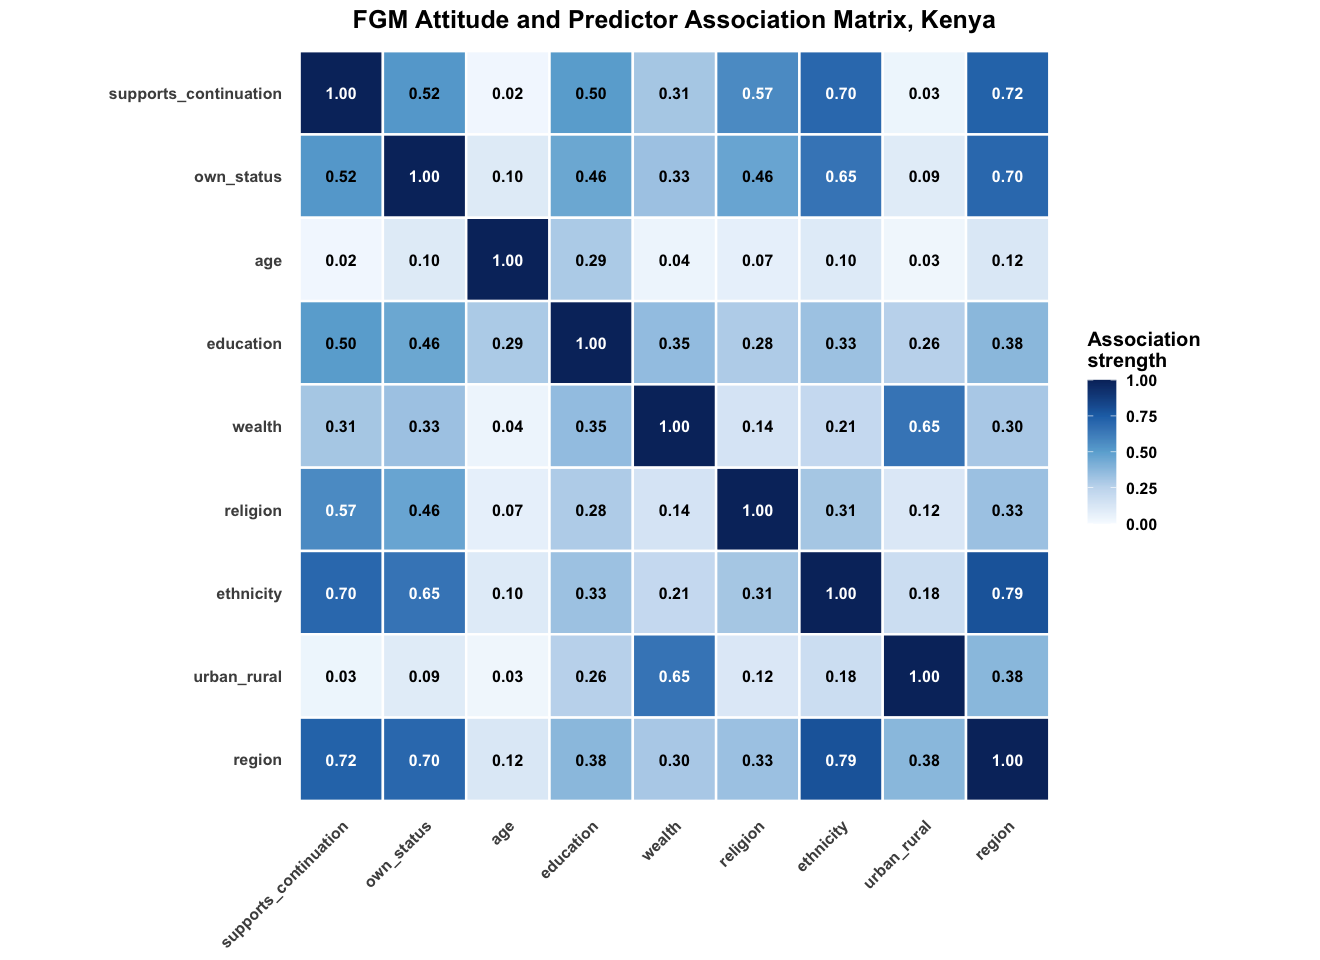

In [6]:
cramers_v_corrected <- function(x, y) {
  keep <- stats::complete.cases(x, y)
  x <- droplevels(as.factor(x[keep]))
  y <- droplevels(as.factor(y[keep]))
  if (length(x) == 0L || nlevels(x) < 2L || nlevels(y) < 2L) return(NA_real_)
  tab <- table(x, y)
  chi2 <- suppressWarnings(as.numeric(stats::chisq.test(tab, correct = FALSE)$statistic))
  n <- sum(tab); r <- nrow(tab); k <- ncol(tab)
  phi2 <- chi2 / n
  phi2c <- max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
  rc <- r - ((r - 1)^2) / (n - 1)
  kc <- k - ((k - 1)^2) / (n - 1)
  den <- min(rc - 1, kc - 1)
  if (!is.finite(den) || den <= 0) return(NA_real_)
  sqrt(phi2c / den)
}

correlation_ratio <- function(x_numeric, y_category) {
  keep <- stats::complete.cases(x_numeric, y_category)
  x <- as.numeric(x_numeric[keep])
  y <- droplevels(as.factor(y_category[keep]))
  if (length(unique(x)) < 2L || nlevels(y) < 2L) return(NA_real_)
  grand_mean <- mean(x)
  groups <- split(x, y)
  between <- sum(vapply(groups, function(z) length(z) * (mean(z) - grand_mean)^2,
                        numeric(1)))
  total <- sum((x - grand_mean)^2)
  if (!is.finite(total) || total <= 0) return(NA_real_)
  sqrt(max(0, min(1, between / total)))
}

mixed_association <- function(x, y) {
  xn <- is.numeric(x); yn <- is.numeric(y)
  if (xn && yn) {
    keep <- stats::complete.cases(x, y)
    if (sum(keep) < 3L || length(unique(x[keep])) < 2L ||
        length(unique(y[keep])) < 2L) return(NA_real_)
    return(abs(stats::cor(x[keep], y[keep], method = "spearman")))
  }
  if (!xn && !yn) return(cramers_v_corrected(x, y))
  if (xn) correlation_ratio(x, y) else correlation_ratio(y, x)
}

association_data <- attitude_all |>
  dplyr::select(supports_continuation, dplyr::all_of(eligible_predictors)) |>
  dplyr::mutate(
    supports_continuation = factor(
      supports_continuation, levels = c(0, 1), labels = c("Stop", "Continue")
    ),
    own_status = factor(own_status, levels = c(0, 1), labels = c("Not cut", "Cut")),
    dplyr::across(dplyr::where(is.character), as.factor)
  )

association_names <- names(association_data)
association_matrix <- matrix(
  NA_real_, length(association_names), length(association_names),
  dimnames = list(association_names, association_names)
)
for (i in seq_along(association_names)) {
  for (j in seq_along(association_names)) {
    association_matrix[i, j] <- if (i == j) 1 else mixed_association(
      association_data[[i]], association_data[[j]]
    )
  }
}

association_long <- as.data.frame(association_matrix) |>
  tibble::rownames_to_column("variable_y") |>
  tidyr::pivot_longer(-variable_y, names_to = "variable_x", values_to = "association") |>
  dplyr::mutate(
    variable_x = factor(variable_x, levels = association_names),
    variable_y = factor(variable_y, levels = rev(association_names)),
    value_label = dplyr::if_else(is.na(association), "NA", sprintf("%.2f", association))
  )

association_plot <- ggplot2::ggplot(
  association_long,
  ggplot2::aes(variable_x, variable_y, fill = association)
) +
  ggplot2::geom_tile(color = "white", linewidth = 0.7) +
  ggplot2::geom_text(
    ggplot2::aes(label = value_label, color = association >= 0.55),
    fontface = "bold", size = 3.4
  ) +
  ggplot2::scale_fill_gradientn(
    colors = c("#F7FBFF", "#C6DBEF", "#6BAED6", "#2171B5", "#08306B"),
    limits = c(0, 1), name = "Association\nstrength", na.value = "grey85"
  ) +
  ggplot2::scale_color_manual(values = c(`FALSE` = "black", `TRUE` = "white"), guide = "none") +
  ggplot2::coord_fixed() +
  ggplot2::labs(
    title = paste("FGM Attitude and Predictor Association Matrix,", country_name),
    x = NULL, y = NULL
  ) +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(hjust = 0.5, size = 15),
    axis.text.x = ggplot2::element_text(angle = 45, hjust = 1),
    panel.grid = ggplot2::element_blank()
  )

print(association_plot)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_association_matrix_v3.png")),
  association_plot, width = 10, height = 8, dpi = 300, bg = "white"
)
readr::write_csv(
  association_long |>
    dplyr::transmute(
      variable_y = as.character(variable_y),
      variable_x = as.character(variable_x), association
    ),
  file.path(output_dir, paste0(country_iso3, "_attitude_association_matrix_v3.csv"))
)

## 6. Design-based direct estimates

These estimates use the DHS sampling weights, PSUs and strata. They remain the
primary design-based population benchmark. The attitude domain comprises women
with a known response to whether FGM should continue.

In [7]:
attitude_design_data <- attitude_all |>
  dplyr::filter(
    !is.na(supports_continuation), is.finite(weight), weight > 0,
    !is.na(psu), !is.na(strata), !is.na(region)
  )

attitude_design <- survey::svydesign(
  ids = ~psu,
  strata = ~strata,
  weights = ~weight,
  data = attitude_design_data,
  nest = TRUE
)

direct_national_raw <- survey::svymean(
  ~supports_continuation, attitude_design, na.rm = TRUE
)
direct_national <- tibble::tibble(
  method = "Design-based direct",
  estimate = unname(stats::coef(direct_national_raw)[1]),
  se = unname(survey::SE(direct_national_raw)[1]),
  lower_ci = pmax(estimate - 1.96 * se, 0),
  upper_ci = pmin(estimate + 1.96 * se, 1)
)

direct_by_region <- survey::svyby(
  ~supports_continuation,
  ~region,
  attitude_design,
  survey::svymean,
  na.rm = TRUE,
  vartype = "se"
) |>
  dplyr::as_tibble() |>
  dplyr::mutate(
    lower_ci = pmax(supports_continuation - 1.96 * se, 0),
    upper_ci = pmin(supports_continuation + 1.96 * se, 1)
  )

cat("=== Direct national support for continuation ===\n")
print(direct_national)
cat("\n=== Direct estimates by region ===\n")
print(direct_by_region, n = Inf)

readr::write_csv(
  direct_national,
  file.path(output_dir, paste0(country_iso3, "_attitude_direct_national_v3.csv"))
)
readr::write_csv(
  direct_by_region,
  file.path(output_dir, paste0(country_iso3, "_attitude_direct_by_state_v3.csv"))
)

=== Direct national support for continuation ===
# A tibble: 1 × 5
  method              estimate      se lower_ci upper_ci
  <chr>                  <dbl>   <dbl>    <dbl>    <dbl>
1 Design-based direct   0.0438 0.00257   0.0387   0.0488

=== Direct estimates by region ===
# A tibble: 47 × 5
   region          supports_continuation      se lower_ci upper_ci
   <chr>                           <dbl>   <dbl>    <dbl>    <dbl>
 1 BARINGO                       0.0522  0.0215  0.0100    0.0944 
 2 BOMET                         0.0552  0.0146  0.0265    0.0839 
 3 BUNGOMA                       0.0184  0.0127  0         0.0434 
 4 BUSIA                         0.00275 0.00274 0         0.00812
 5 ELGEYO MARAKWET               0.0107  0.00715 0         0.0248 
 6 EMBU                          0.0314  0.0113  0.00923   0.0535 
 7 GARISSA                       0.714   0.0626  0.592     0.837  
 8 HOMA BAY                      0.0582  0.0150  0.0288    0.0876 
 9 ISIOLO                        0.25

## 7. Regional boundaries and BYM2 adjacency

In [8]:
if (!file.exists(shapefile_path)) stop("Boundary shapefile not found: ", shapefile_path)

boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |>
  sf::st_make_valid()

if (!region_var_shapefile %in% names(boundaries)) {
  stop("Boundary field not found: ", region_var_shapefile)
}

boundaries <- boundaries |>
  dplyr::mutate(
    .region_key = standardize_region(.data[[region_var_shapefile]])
  )

shp_regions <- boundaries$.region_key
if (anyDuplicated(shp_regions)) stop("Boundary region names are not unique")

unmatched_survey <- setdiff(unique(attitude_all$region), shp_regions)
unmatched_shape <- setdiff(shp_regions, unique(attitude_all$region))
if (length(unmatched_survey) > 0L) {
  stop("Survey regions absent from boundary: ", paste(unmatched_survey, collapse = ", "))
}
if (length(unmatched_shape) > 0L) {
  warning("Boundary regions absent from attitude data: ", paste(unmatched_shape, collapse = ", "))
}

adjacency <- spdep::poly2nb(boundaries, row.names = shp_regions, queen = TRUE)
adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)

cat("Boundary regions:", nrow(boundaries), "\n")
cat("Survey regions matched:", length(intersect(unique(attitude_all$region), shp_regions)), "\n")

Boundary regions: 47 
Survey regions matched: 47 


## 8. Prepare the normalized survey-weighted model data

Region is represented by the BYM2 term rather than duplicated as a fixed
effect. Age is fitted flexibly using a second-order random walk. The remaining
selected variables enter as fixed effects. Mean-one weights preserve the
observed likelihood scale while incorporating relative DHS sampling weights.

In [9]:
model_predictors <- setdiff(selected_predictors, "region")
fixed_predictors <- setdiff(model_predictors, "age")

required_model_columns <- c(
  "supports_continuation", "region", "weight", model_predictors
)
missing_model_columns <- setdiff(required_model_columns, names(attitude_all))
if (length(missing_model_columns) > 0L) {
  stop("Missing model columns: ", paste(missing_model_columns, collapse = ", "))
}

model_data <- attitude_all |>
  dplyr::mutate(
    region_id = match(region, shp_regions),
    own_status = factor(own_status, levels = c(0, 1), labels = c("Not cut", "Cut")),
    education = factor(education),
    wealth = factor(wealth),
    religion = factor(religion),
    ethnicity = factor(ethnicity),
    urban_rural = factor(urban_rural),
    age = as.numeric(age)
  ) |>
  dplyr::filter(
    !is.na(supports_continuation), !is.na(region_id),
    is.finite(weight), weight > 0, is.finite(age)
  ) |>
  tidyr::drop_na(dplyr::all_of(model_predictors)) |>
  droplevels() |>
  dplyr::mutate(
    age_id = as.integer(age - min(age) + 1L),
    pseudo_weight = weight / mean(weight),
    model_row = dplyr::row_number()
  )

if (!all(model_data$supports_continuation %in% c(0, 1))) {
  stop("The attitude outcome must contain only 0/1")
}

cat("Model respondents:", nrow(model_data), "\n")
cat("Model regions:", dplyr::n_distinct(model_data$region_id), "\n")
cat("Mean normalized weight:", mean(model_data$pseudo_weight), "\n")
cat("Fixed predictors:", paste(fixed_predictors, collapse = ", "), "\n")

Model respondents: 15890 
Model regions: 47 
Mean normalized weight: 1 
Fixed predictors: own_status, ethnicity, education, wealth, religion, urban_rural 


## 9. Survey-weighted spatial models

Two models are fitted to the same respondents: a spatial-only benchmark and a
full covariate-adjusted model. INLA likelihood weights create a survey-weighted
pseudo-likelihood; they do not reproduce the full stratified/clustered design
variance. Consequently, model intervals are described as pseudo-posterior.

In [10]:
fixed_part <- if (length(fixed_predictors) > 0L) {
  paste(fixed_predictors, collapse = " + ")
} else {
  "1"
}

spatial_formula <- stats::as.formula(
  "supports_continuation ~ 1 + f(region_id, model = 'bym2', graph = adjacency_matrix, scale.model = TRUE)"
)

adjusted_formula <- stats::as.formula(paste0(
  "supports_continuation ~ ", fixed_part,
  " + f(age_id, model = 'rw2', constr = TRUE, scale.model = TRUE)",
  " + f(region_id, model = 'bym2', graph = adjacency_matrix, scale.model = TRUE)"
))

fit_attitude_model <- function(formula) {
  INLA::inla(
    formula,
    family = "binomial",
    data = model_data,
    weights = model_data$pseudo_weight,
    control.predictor = list(compute = TRUE, link = 1),
    control.compute = list(dic = TRUE, waic = TRUE, cpo = TRUE, config = TRUE),
    control.inla = list(control.vb = list(enable = FALSE))
  )
}

cat("Fitting spatial-only benchmark...\n")
spatial_only_model <- fit_attitude_model(spatial_formula)

cat("Fitting covariate-adjusted spatial model...\n")
adjusted_attitude_model <- fit_attitude_model(adjusted_formula)

model_fit_comparison <- tibble::tibble(
  model = c("Spatial only", "Covariate adjusted"),
  dic = c(spatial_only_model$dic$dic, adjusted_attitude_model$dic$dic),
  waic = c(spatial_only_model$waic$waic, adjusted_attitude_model$waic$waic),
  failed_cpo = c(
    sum(spatial_only_model$cpo$failure > 0, na.rm = TRUE),
    sum(adjusted_attitude_model$cpo$failure > 0, na.rm = TRUE)
  )
)

print(model_fit_comparison)
cat("\n=== Adjusted model fixed effects, log-odds scale ===\n")
print(round(adjusted_attitude_model$summary.fixed[, 1:5, drop = FALSE], 3))

readr::write_csv(
  model_fit_comparison,
  file.path(output_dir, paste0(country_iso3, "_attitude_model_fit_v3.csv"))
)
readr::write_csv(
  tibble::rownames_to_column(
    as.data.frame(adjusted_attitude_model$summary.fixed), "term"
  ),
  file.path(output_dir, paste0(country_iso3, "_attitude_fixed_effects_v3.csv"))
)

Fitting spatial-only benchmark...
Fitting covariate-adjusted spatial model...
# A tibble: 2 × 4
  model                dic  waic failed_cpo
  <chr>              <dbl> <dbl>      <int>
1 Spatial only       3788. 3797.          0
2 Covariate adjusted 3199. 3245.          0

=== Adjusted model fixed effects, log-odds scale ===
                               mean    sd 0.025quant 0.5quant 0.975quant
(Intercept)                  -5.494 0.394     -6.267   -5.494     -4.721
own_statusCut                 1.994 0.156      1.689    1.994      2.299
ethnicitykamba               -0.981 0.385     -1.739   -0.980     -0.229
ethnicitykikuyu              -0.801 0.313     -1.418   -0.800     -0.192
ethnicitykisii               -0.169 0.294     -0.748   -0.168      0.405
ethnicityluhya               -0.669 0.331     -1.320   -0.668     -0.022
ethnicityluo                  0.661 0.300      0.069    0.662      1.246
ethnicityother               -0.498 0.245     -0.981   -0.497     -0.019
ethnicitysomali  

## 10. Posterior regional and national estimates

For each posterior draw, complete respondent linear predictors are converted to
probabilities and aggregated using the original DHS weights. This preserves the
observed weighted covariate distribution within every region.

In [11]:
summarise_posterior_attitude <- function(
    model, model_data, n_draws = 500L, seed = 20260918L) {

  if (nrow(model$summary.fitted.values) != nrow(model_data)) {
    stop("Fitted-value rows do not align with model data")
  }

  region_lookup <- model_data |>
    dplyr::distinct(region, region_id) |>
    dplyr::arrange(region_id)
  region_ids <- region_lookup$region_id
  rows_by_region <- lapply(region_ids, function(id) which(model_data$region_id == id))

  set.seed(seed)
  posterior_samples <- INLA::inla.posterior.sample(
    n_draws, model, use.improved.mean = FALSE, skew.corr = FALSE
  )

  latent_names <- rownames(posterior_samples[[1L]]$latent)
  predictor_rows <- grep("^Predictor:", latent_names)
  predictor_numbers <- suppressWarnings(as.integer(sub(
    "^Predictor:", "", latent_names[predictor_rows]
  )))
  if (!anyNA(predictor_numbers)) {
    predictor_rows <- predictor_rows[order(predictor_numbers)]
  }
  if (length(predictor_rows) != nrow(model_data)) {
    stop("Posterior predictors do not align with model rows")
  }

  draw_matrix <- vapply(
    posterior_samples,
    function(sample_draw) {
      probability <- stats::plogis(as.numeric(
        sample_draw$latent[predictor_rows, 1L]
      ))
      state_values <- vapply(rows_by_region, function(rows) {
        stats::weighted.mean(probability[rows], model_data$weight[rows])
      }, numeric(1L))
      national_value <- stats::weighted.mean(probability, model_data$weight)
      c(state_values, national_value)
    },
    numeric(length(region_ids) + 1L)
  )

  if (is.null(dim(draw_matrix))) {
    draw_matrix <- matrix(draw_matrix, nrow = length(region_ids) + 1L)
  }

  state_draws <- draw_matrix[seq_along(region_ids), , drop = FALSE]
  national_draws <- draw_matrix[length(region_ids) + 1L, ]

  state_summary <- region_lookup |>
    dplyr::mutate(
      estimate = rowMeans(state_draws),
      lower_ci = apply(state_draws, 1L, stats::quantile, 0.025, names = FALSE),
      upper_ci = apply(state_draws, 1L, stats::quantile, 0.975, names = FALSE),
      n_unweighted = vapply(rows_by_region, length, integer(1L)),
      sum_survey_weight = vapply(rows_by_region, function(rows) {
        sum(model_data$weight[rows])
      }, numeric(1L))
    )

  national_summary <- tibble::tibble(
    estimate = mean(national_draws),
    lower_ci = stats::quantile(national_draws, 0.025, names = FALSE),
    upper_ci = stats::quantile(national_draws, 0.975, names = FALSE)
  )

  list(state = state_summary, national = national_summary)
}

spatial_summary <- summarise_posterior_attitude(
  spatial_only_model, model_data, posterior_draws, seed = 20260918L
)
adjusted_summary <- summarise_posterior_attitude(
  adjusted_attitude_model, model_data, posterior_draws, seed = 20260919L
)

spatial_state <- spatial_summary$state |>
  dplyr::rename(
    spatial_only = estimate,
    spatial_lower = lower_ci,
    spatial_upper = upper_ci
  )

adjusted_state <- adjusted_summary$state |>
  dplyr::rename(
    adjusted_support = estimate,
    adjusted_lower = lower_ci,
    adjusted_upper = upper_ci
  ) |>
  dplyr::left_join(
    direct_by_region |>
      dplyr::select(
        region,
        direct_support = supports_continuation,
        direct_se = se,
        direct_lower = lower_ci,
        direct_upper = upper_ci
      ),
    by = "region"
  ) |>
  dplyr::left_join(
    spatial_state |>
      dplyr::select(region, spatial_only, spatial_lower, spatial_upper),
    by = "region"
  )

adjusted_national <- adjusted_summary$national |>
  dplyr::mutate(method = "Covariate-adjusted spatial", .before = 1)
spatial_national <- spatial_summary$national |>
  dplyr::mutate(method = "Spatial only", .before = 1)
national_comparison <- dplyr::bind_rows(
  direct_national |>
    dplyr::select(method, estimate, lower_ci, upper_ci),
  spatial_national,
  adjusted_national
)

cat("=== National comparison ===\n")
print(national_comparison)
cat("\n=== Regional estimates ===\n")
print(adjusted_state, n = Inf)

readr::write_csv(
  adjusted_state,
  file.path(output_dir, paste0(country_iso3, "_attitude_covariate_adjusted_by_state_v3.csv"))
)
readr::write_csv(
  national_comparison,
  file.path(output_dir, paste0(country_iso3, "_attitude_national_comparison_v3.csv"))
)

=== National comparison ===
# A tibble: 3 × 4
  method                     estimate lower_ci upper_ci
  <chr>                         <dbl>    <dbl>    <dbl>
1 Design-based direct          0.0438   0.0387   0.0488
2 Spatial only                 0.0448   0.0423   0.0479
3 Covariate-adjusted spatial   0.0450   0.0426   0.0477

=== Regional estimates ===
# A tibble: 47 × 14
   region  region_id adjusted_support adjusted_lower adjusted_upper n_unweighted
   <chr>       <int>            <dbl>          <dbl>          <dbl>        <int>
 1 BARINGO         1          0.0500         0.0294          0.0771          334
 2 BOMET           2          0.0549         0.0347          0.0796          388
 3 BUNGOMA         3          0.0172         0.00968         0.0270          405
 4 BUSIA           4          0.00687        0.00245         0.0152          396
 5 ELGEYO…         5          0.0239         0.00889         0.0516          280
 6 EMBU            6          0.0301         0.0135        

## 11. Covariate-adjusted attitude map

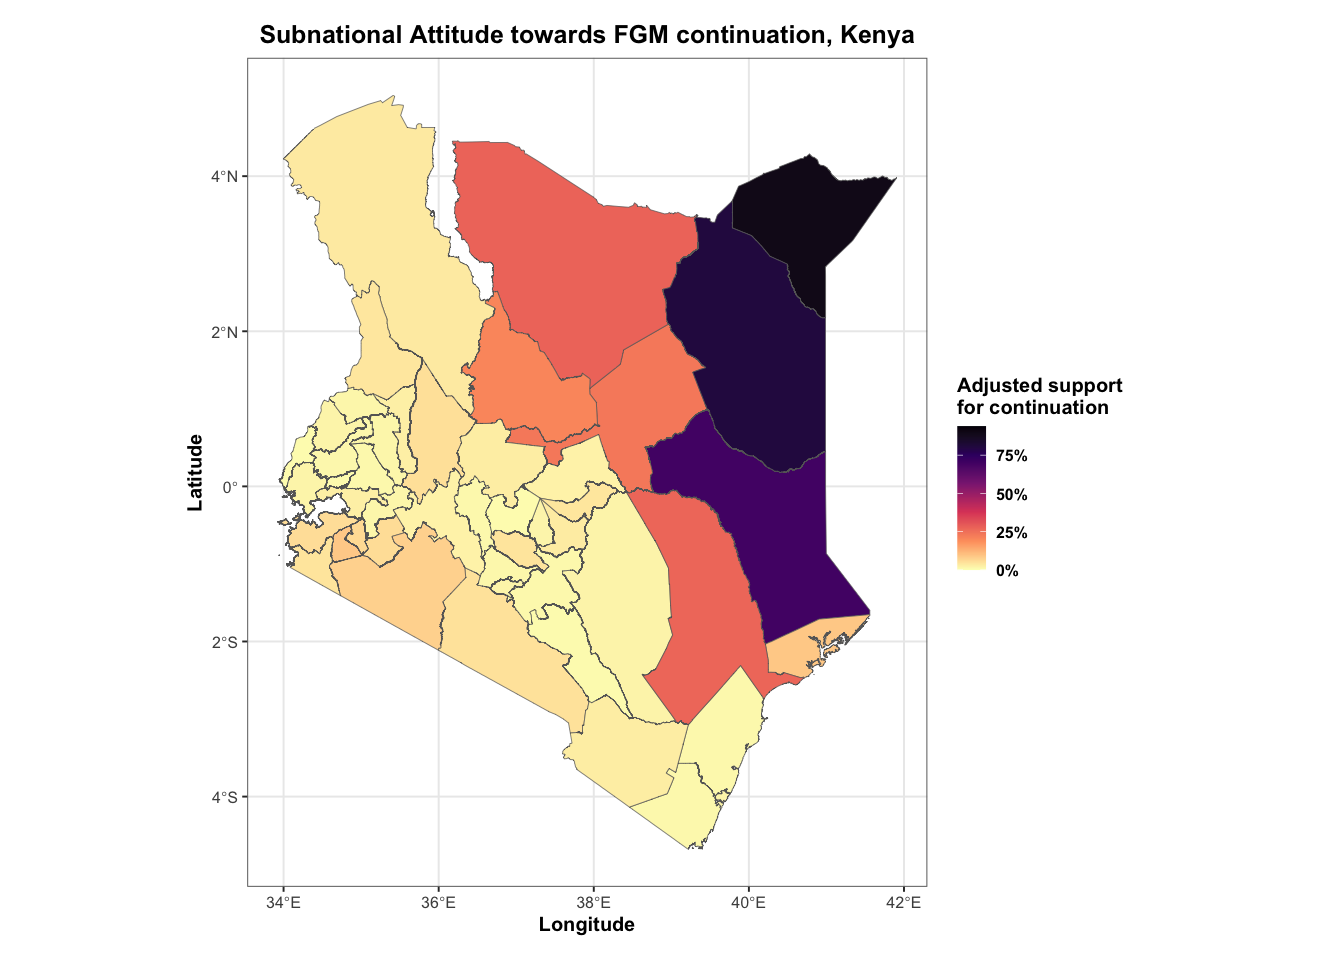

In [12]:
attitude_map_data <- boundaries |>
  dplyr::left_join(adjusted_state, by = c(".region_key" = "region"))

adjusted_attitude_map <- ggplot2::ggplot(attitude_map_data) +
  ggplot2::geom_sf(
    ggplot2::aes(fill = adjusted_support),
    color = "grey40", linewidth = 0.20
  ) +
  ggplot2::scale_fill_viridis_c(
    name = "Adjusted support\nfor continuation",
    option = "magma", direction = -1,
    labels = scales::percent_format(accuracy = 1),
    limits = c(0, max(attitude_map_data$adjusted_upper, na.rm = TRUE)),
    oob = scales::squish, na.value = "grey90"
  ) +
  ggplot2::coord_sf(datum = sf::st_crs(4326)) +
  ggplot2::labs(
    title = paste("Subnational Attitude towards FGM continuation,", country_name),
    x = "Longitude", y = "Latitude"
  ) +
  ggplot2::theme_bw(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(size = 15, hjust = 0.5),
    legend.title = ggplot2::element_text(face = "bold"),
    panel.border = ggplot2::element_rect(color = "grey40", fill = NA),
    plot.margin = ggplot2::margin(15, 15, 15, 15)
  )

print(adjusted_attitude_map)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_covariate_adjusted_map_v3.png")),
  adjusted_attitude_map, width = 9, height = 8, dpi = 300, bg = "white"
)

## 12. Residual geographic pattern

The BYM2 effect shows geographic variation remaining after adjustment for the
selected composition variables. It is a relative log-odds effect, not an
attitude-prevalence estimate.

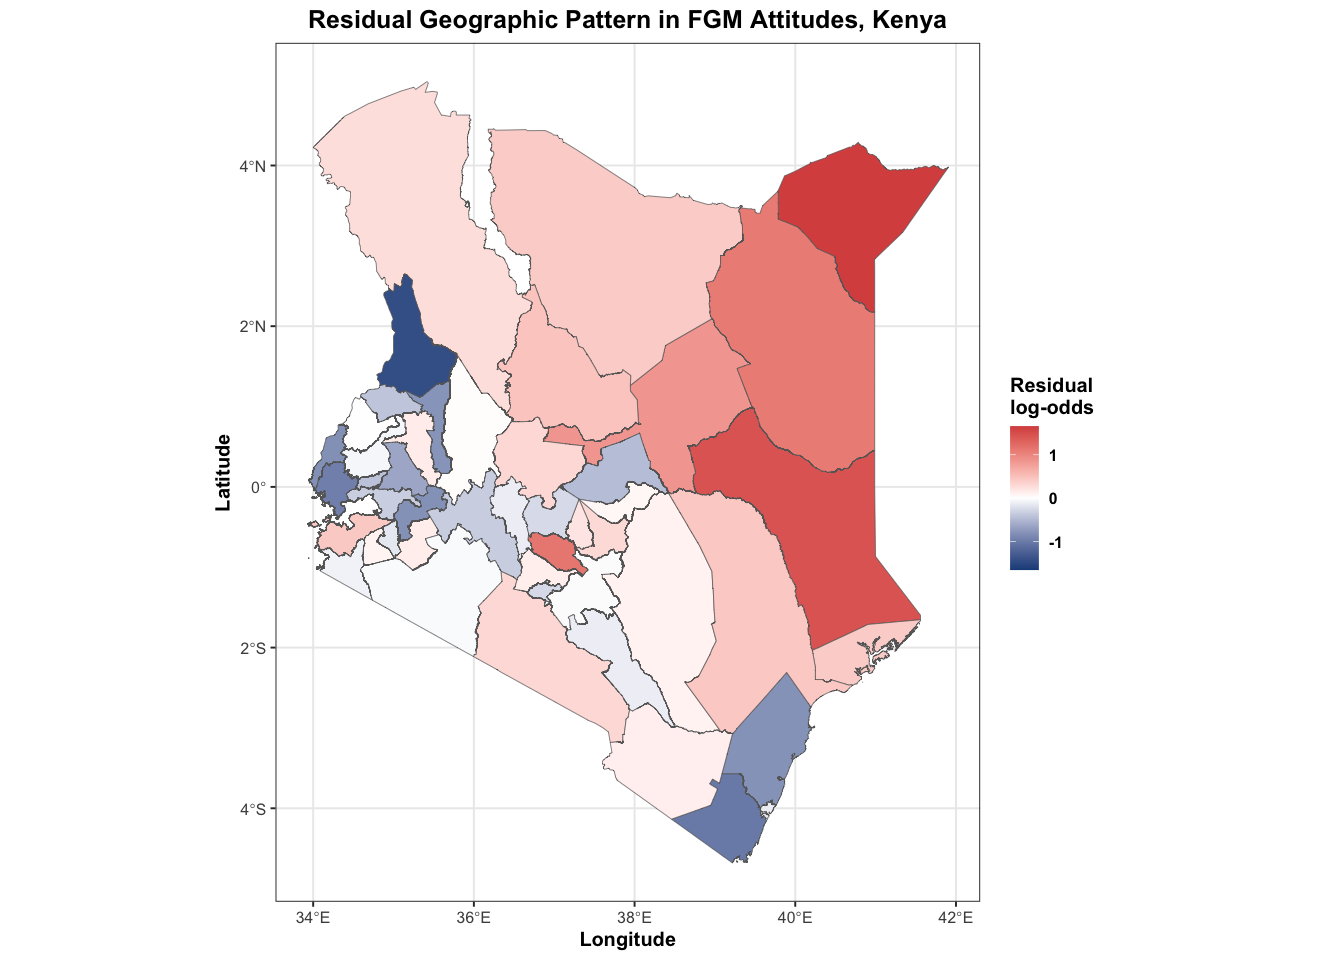

In [13]:
region_lookup <- model_data |>
  dplyr::distinct(region, region_id) |>
  dplyr::arrange(region_id)

residual_state <- adjusted_attitude_model$summary.random$region_id |>
  dplyr::filter(ID %in% region_lookup$region_id) |>
  dplyr::transmute(
    region_id = ID,
    residual_effect = mean,
    residual_lower = `0.025quant`,
    residual_upper = `0.975quant`
  ) |>
  dplyr::left_join(region_lookup, by = "region_id")

residual_map_data <- boundaries |>
  dplyr::left_join(residual_state, by = c(".region_key" = "region"))

residual_limit <- max(abs(residual_map_data$residual_effect), na.rm = TRUE)
residual_map <- ggplot2::ggplot(residual_map_data) +
  ggplot2::geom_sf(
    ggplot2::aes(fill = residual_effect), color = "grey40", linewidth = 0.20
  ) +
  ggplot2::scale_fill_gradient2(
    name = "Residual\nlog-odds",
    low = "#1D4E89", mid = "white", high = "#D9534F",
    midpoint = 0, limits = c(-residual_limit, residual_limit)
  ) +
  ggplot2::labs(
    title = paste("Residual Geographic Pattern in FGM Attitudes,", country_name),
    x = "Longitude", y = "Latitude"
  ) +
  ggplot2::theme_bw(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(size = 15, hjust = 0.5)
  )

print(residual_map)
readr::write_csv(
  residual_state,
  file.path(output_dir, paste0(country_iso3, "_attitude_residual_spatial_effect_v3.csv"))
)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_residual_map_v3.png")),
  residual_map, width = 9, height = 8, dpi = 300, bg = "white"
)

## 13. Validation and comparison

# A tibble: 1 × 5
  states_compared correlation_direct_adjusted mean_absolute_difference
            <int>                       <dbl>                    <dbl>
1              47                       0.999                  0.00566
# ℹ 2 more variables: root_mean_squared_difference <dbl>,
#   maximum_absolute_difference <dbl>


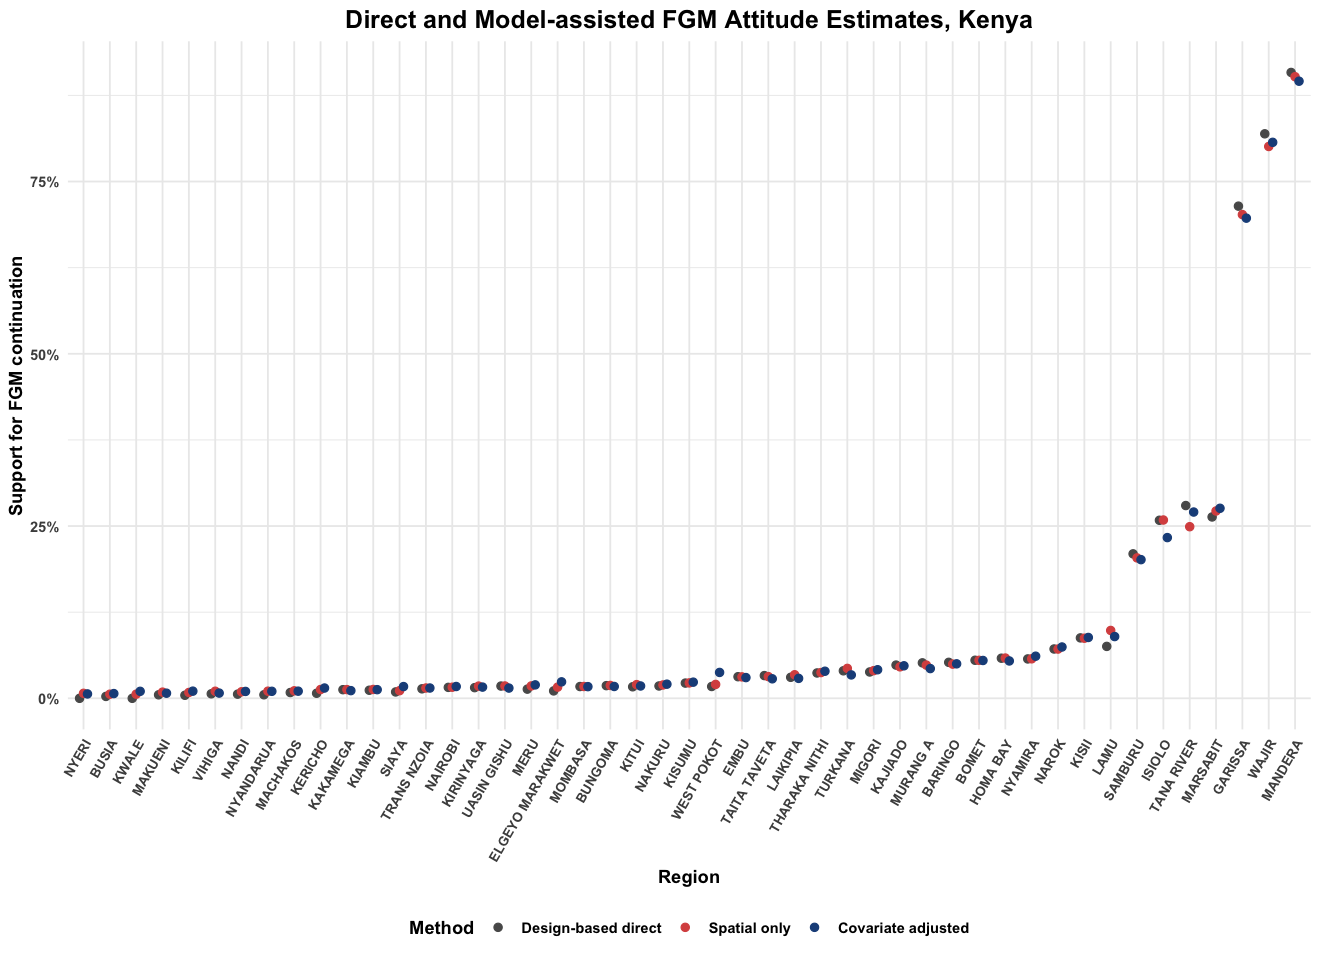

In [14]:
validation_metrics <- adjusted_state |>
  dplyr::summarise(
    states_compared = sum(stats::complete.cases(direct_support, adjusted_support)),
    correlation_direct_adjusted = stats::cor(
      direct_support, adjusted_support, use = "complete.obs"
    ),
    mean_absolute_difference = mean(
      abs(adjusted_support - direct_support), na.rm = TRUE
    ),
    root_mean_squared_difference = sqrt(mean(
      (adjusted_support - direct_support)^2, na.rm = TRUE
    )),
    maximum_absolute_difference = max(
      abs(adjusted_support - direct_support), na.rm = TRUE
    )
  )

validation_long <- adjusted_state |>
  dplyr::select(region, direct_support, spatial_only, adjusted_support) |>
  tidyr::pivot_longer(
    -region, names_to = "method", values_to = "support"
  ) |>
  dplyr::mutate(
    method = factor(
      method,
      levels = c("direct_support", "spatial_only", "adjusted_support"),
      labels = c("Design-based direct", "Spatial only", "Covariate adjusted")
    )
  )

validation_plot <- ggplot2::ggplot(
  validation_long,
  ggplot2::aes(x = reorder(region, support), y = support, color = method, group = method)
) +
  ggplot2::geom_point(position = ggplot2::position_dodge(width = 0.45), size = 2) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::scale_color_manual(
    values = c(
      "Design-based direct" = "grey35",
      "Spatial only" = "#D9534F",
      "Covariate adjusted" = "#1D4E89"
    )
  ) +
  ggplot2::labs(
    title = paste("Direct and Model-assisted FGM Attitude Estimates,", country_name),
    x = "Region", y = "Support for FGM continuation", color = "Method"
  ) +
  ggplot2::theme_minimal(base_size = 11) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(hjust = 0.5, size = 15),
    axis.text.x = ggplot2::element_text(angle = 60, hjust = 1, size = 8),
    legend.position = "bottom"
  )

print(validation_metrics)
print(validation_plot)

readr::write_csv(
  validation_metrics,
  file.path(output_dir, paste0(country_iso3, "_attitude_validation_metrics_v3.csv"))
)
readr::write_csv(
  validation_long,
  file.path(output_dir, paste0(country_iso3, "_attitude_validation_comparison_v3.csv"))
)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_validation_v3.png")),
  validation_plot, width = 12, height = 7, dpi = 300, bg = "white"
)

## 14. Interpretation and limitations

- The design-based national and regional estimates are the survey-design benchmark.
- The adjusted model uses normalized DHS weights in a pseudo-likelihood and
  again during posterior aggregation. Its intervals are pseudo-posterior, not
  fully design-based confidence intervals.
- Estimates apply to interviewed women with a known response to the attitude
  question; they should not be described as the views of daughters.
- Random-forest importance is descriptive and can favor variables with many
  categories. It ranks predictors but does not establish causality.
- Own FGM status and age are retained a priori. Region is represented once, by
  the BYM2 effect, rather than duplicated as a fixed effect.
- The previous cluster mean of the outcome is not used as a predictor, removing
  the outcome leakage present in v2.
- Predictions are averaged over the observed survey-weighted regional composition.
- County estimates with small effective samples or wide uncertainty intervals
  require additional caution.
  Full MRP would require external population counts for joint demographic cells.

# Part 2: Men's attitudes

Sections 15–23 repeat the women's analysis (sections 2–13) for men. They use the men's
recode prepared by `00_EDA_DHS_Country_Year_v2.ipynb` (`KEN_attitude_men.rds`). The
outcome, candidate covariates, county boundaries, BYM2 graph, model specification and
posterior aggregation are the same as for women. Section 24 compares women and men.

Two differences from the women's analysis:

- Men have no own-FGM-status variable, so it is not a candidate predictor.
- Men are restricted to ages 15–49 to match the women's age range. Kenya interviewed men
  up to age 54.


## 15. Men: load the attitude data

Same outcome as for women: 1 if the man says FGM should continue, 0 if it should be
stopped. Men who answered "depends" or "don't know" are not in the file.


In [15]:
men_max_age <- 49  # match the women's 15-49 age range

attitude_men_path <- file.path(combined_data_dir, paste0(country_iso3, "_attitude_men.rds"))
if (!file.exists(attitude_men_path)) {
  stop("Missing: ", attitude_men_path, ". Run 00_EDA_DHS_Country_Year_v2.ipynb first.")
}

attitude_men_raw <- readRDS(attitude_men_path)
if (anyDuplicated(attitude_men_raw$id)) stop("Duplicate respondent IDs in men's attitude data")

attitude_men <- attitude_men_raw |>
  dplyr::mutate(region = standardize_region(region), age = as.numeric(age)) |>
  dplyr::filter(age <= men_max_age)

unmatched_men <- setdiff(unique(attitude_men$region), shp_regions)
if (length(unmatched_men) > 0L) {
  stop("Men's regions absent from boundary: ", paste(unmatched_men, collapse = ", "))
}

cat("Men with a continue/stop answer, ages 15 to", men_max_age, ":", nrow(attitude_men),
    "(", nrow(attitude_men_raw) - nrow(attitude_men), "men aged 50+ excluded )\n")
cat("Supports continuation:", sum(attitude_men$supports_continuation == 1), "\n")
cat("Supports stopping:", sum(attitude_men$supports_continuation == 0), "\n")
cat("Age range:", paste(range(attitude_men$age), collapse = " to "), "\n")
cat("Regions:", dplyr::n_distinct(attitude_men$region), "\n")

dplyr::glimpse(attitude_men)


Men with a continue/stop answer, ages 15 to 49 : 12878 ( 745 men aged 50+ excluded )
Supports continuation: 1237 
Supports stopping: 11641 
Age range: 15 to 49 
Regions: 47 
Rows: 12,878
Columns: 21
$ id                    <chr> "2022-m-1-4-1", "2022-m-1-13-3", "2022-m-1-13-4"…
$ sex                   <chr> "male", "male", "male", "male", "male", "male", …
$ survey_type           <chr> "DHS", "DHS", "DHS", "DHS", "DHS", "DHS", "DHS",…
$ survey_year           <int> 2022, 2022, 2022, 2022, 2022, 2022, 2022, 2022, …
$ country               <chr> "KEN", "KEN", "KEN", "KEN", "KEN", "KEN", "KEN",…
$ region                <chr> "MOMBASA", "MOMBASA", "MOMBASA", "MOMBASA", "MOM…
$ cluster               <dbl> 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, …
$ urban_rural           <chr> "urban", "urban", "urban", "urban", "urban", "ur…
$ weight                <dbl> 1.221221, 1.221221, 1.221221, 1.221221, 1.221221…
$ psu                   <dbl> 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, …
$

## 16. Men: predictor screening and final predictor selection

Same screen as sections 3–4: missingness, random-forest permutation importance against
`supports_continuation`, then adjusted VIF. Age is retained a priori, as for women.


In [16]:
candidate_predictors_men <- setdiff(candidate_predictors, "own_status")

missingness_men <- attitude_men |>
  dplyr::summarise(
    dplyr::across(dplyr::all_of(candidate_predictors_men), ~mean(is.na(.)))
  ) |>
  tidyr::pivot_longer(
    dplyr::everything(), names_to = "variable", values_to = "proportion_missing"
  ) |>
  dplyr::mutate(percent_missing = 100 * proportion_missing)

print(missingness_men)

eligible_predictors_men <- missingness_men |>
  dplyr::filter(proportion_missing < missingness_threshold) |>
  dplyr::pull(variable)

rf_data_men <- attitude_men |>
  dplyr::select(supports_continuation, dplyr::all_of(eligible_predictors_men)) |>
  tidyr::drop_na() |>
  dplyr::mutate(
    supports_continuation = factor(supports_continuation),
    dplyr::across(dplyr::where(is.character), as.factor)
  )

set.seed(20260928)
rf_model_men <- randomForest::randomForest(
  supports_continuation ~ ., data = rf_data_men,
  ntree = 500, importance = TRUE
)

rf_importance_men <- randomForest::importance(rf_model_men)
importance_column_men <- if ("MeanDecreaseAccuracy" %in% colnames(rf_importance_men)) {
  "MeanDecreaseAccuracy"
} else {
  "MeanDecreaseGini"
}

importance_ranked_men <- rf_importance_men |>
  as.data.frame() |>
  tibble::rownames_to_column("variable") |>
  dplyr::arrange(dplyr::desc(.data[[importance_column_men]]))

cat("Rows in men's feature screen:", nrow(rf_data_men), "\n")
print(importance_ranked_men)

vif_check_model_men <- stats::glm(
  stats::reformulate(eligible_predictors_men, response = "supports_continuation"),
  data = rf_data_men, family = stats::binomial()
)
vif_raw_men <- car::vif(vif_check_model_men)
vif_adjusted_men <- if (is.matrix(vif_raw_men)) vif_raw_men[, "GVIF^(1/(2*Df))"] else sqrt(vif_raw_men)

vif_table_men <- tibble::tibble(
  variable = names(vif_adjusted_men), adjusted_vif = as.numeric(vif_adjusted_men)
) |>
  dplyr::arrange(dplyr::desc(adjusted_vif))
print(vif_table_men)

vif_flagged_men <- vif_table_men |>
  dplyr::filter(adjusted_vif > vif_threshold) |>
  dplyr::pull(variable)

selected_predictors_men <- unique(c("age", setdiff(importance_ranked_men$variable, vif_flagged_men)))
selected_predictors_men <- selected_predictors_men[selected_predictors_men %in% eligible_predictors_men]

cat("Final men's attitude predictor list:\n")
print(selected_predictors_men)
cat("Region will be represented by the BYM2 effect rather than a fixed effect.\n")

readr::write_csv(importance_ranked_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_feature_importance_v3.csv")))
readr::write_csv(vif_table_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_vif_v3.csv")))
saveRDS(selected_predictors_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_selected_predictors_v3.rds")))
readr::write_csv(tibble::tibble(variable = selected_predictors_men),
  file.path(output_dir, paste0(country_iso3, "_attitude_men_selected_predictors_v3.csv")))


# A tibble: 7 × 3
  variable    proportion_missing percent_missing
  <chr>                    <dbl>           <dbl>
1 age                          0               0
2 education                    0               0
3 wealth                       0               0
4 religion                     0               0
5 ethnicity                    0               0
6 urban_rural                  0               0
7 region                       0               0
Rows in men's feature screen: 12878 
     variable         0         1 MeanDecreaseAccuracy MeanDecreaseGini
1      region 49.475028 16.643623            71.320354         518.5629
2   ethnicity 38.873473 20.886412            42.228499         254.6401
3   education 20.143060 44.685871            41.739975         143.8826
4    religion 21.565195 30.067505            37.410648         194.2564
5      wealth 21.041004 26.105961            30.596517         111.6321
6 urban_rural 26.570610  6.944574            29.400040          33.3140


## 17. Men: mixed-variable association matrix

Same measures as section 5.


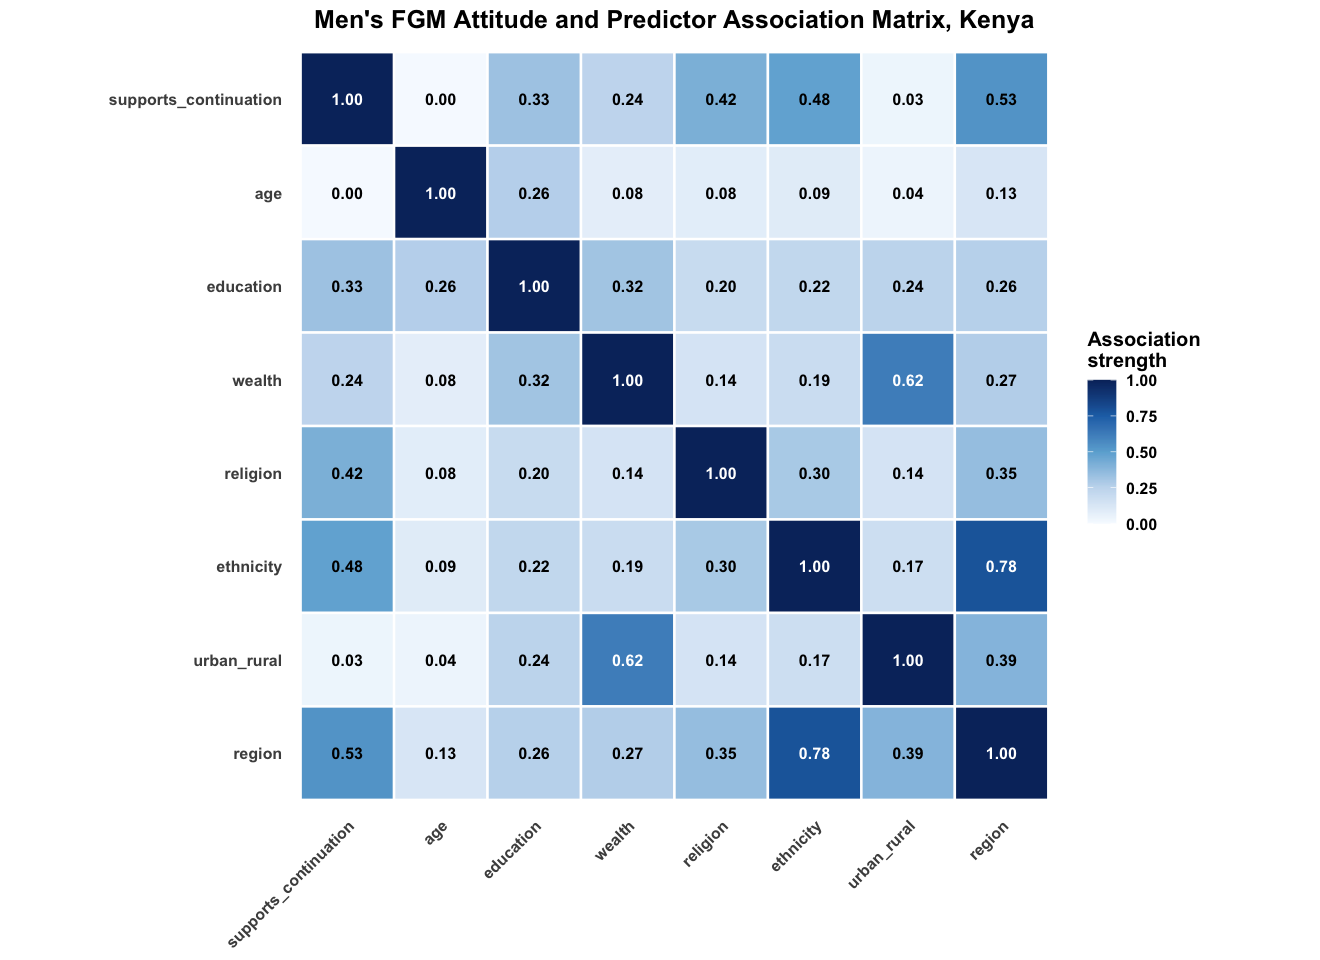

In [17]:
association_data_men <- attitude_men |>
  dplyr::select(supports_continuation, dplyr::all_of(eligible_predictors_men)) |>
  dplyr::mutate(
    supports_continuation = factor(
      supports_continuation, levels = c(0, 1), labels = c("Stop", "Continue")
    ),
    dplyr::across(dplyr::where(is.character), as.factor)
  )

association_names_men <- names(association_data_men)
association_matrix_men <- matrix(
  NA_real_, length(association_names_men), length(association_names_men),
  dimnames = list(association_names_men, association_names_men)
)
for (i in seq_along(association_names_men)) {
  for (j in seq_along(association_names_men)) {
    association_matrix_men[i, j] <- if (i == j) 1 else mixed_association(
      association_data_men[[i]], association_data_men[[j]]
    )
  }
}

association_long_men <- as.data.frame(association_matrix_men) |>
  tibble::rownames_to_column("variable_y") |>
  tidyr::pivot_longer(-variable_y, names_to = "variable_x", values_to = "association") |>
  dplyr::mutate(
    variable_x = factor(variable_x, levels = association_names_men),
    variable_y = factor(variable_y, levels = rev(association_names_men)),
    value_label = dplyr::if_else(is.na(association), "NA", sprintf("%.2f", association))
  )

association_plot_men <- ggplot2::ggplot(
  association_long_men,
  ggplot2::aes(variable_x, variable_y, fill = association)
) +
  ggplot2::geom_tile(color = "white", linewidth = 0.7) +
  ggplot2::geom_text(
    ggplot2::aes(label = value_label, color = association >= 0.55),
    fontface = "bold", size = 3.4
  ) +
  ggplot2::scale_fill_gradientn(
    colors = c("#F7FBFF", "#C6DBEF", "#6BAED6", "#2171B5", "#08306B"),
    limits = c(0, 1), name = "Association\nstrength", na.value = "grey85"
  ) +
  ggplot2::scale_color_manual(values = c(`FALSE` = "black", `TRUE` = "white"), guide = "none") +
  ggplot2::coord_fixed() +
  ggplot2::labs(
    title = paste("Men's FGM Attitude and Predictor Association Matrix,", country_name),
    x = NULL, y = NULL
  ) +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(hjust = 0.5, size = 15),
    axis.text.x = ggplot2::element_text(angle = 45, hjust = 1),
    panel.grid = ggplot2::element_blank()
  )

print(association_plot_men)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_men_association_matrix_v3.png")),
  association_plot_men, width = 10, height = 8, dpi = 300, bg = "white"
)
readr::write_csv(
  association_long_men |>
    dplyr::transmute(variable_y = as.character(variable_y),
                     variable_x = as.character(variable_x), association),
  file.path(output_dir, paste0(country_iso3, "_attitude_men_association_matrix_v3.csv"))
)


## 18. Men: design-based direct estimates

Men's DHS weights (`mv005`), PSUs and strata, as in section 6.


In [18]:
men_design_data <- attitude_men |>
  dplyr::filter(
    !is.na(supports_continuation), is.finite(weight), weight > 0,
    !is.na(psu), !is.na(strata), !is.na(region)
  )

men_design <- survey::svydesign(
  ids = ~psu, strata = ~strata, weights = ~weight,
  data = men_design_data, nest = TRUE
)

direct_national_men_raw <- survey::svymean(~supports_continuation, men_design, na.rm = TRUE)
direct_national_men <- tibble::tibble(
  method = "Design-based direct",
  estimate = unname(stats::coef(direct_national_men_raw)[1]),
  se = unname(survey::SE(direct_national_men_raw)[1]),
  lower_ci = pmax(estimate - 1.96 * se, 0),
  upper_ci = pmin(estimate + 1.96 * se, 1)
)

direct_by_region_men <- survey::svyby(
  ~supports_continuation, ~region, men_design, survey::svymean,
  na.rm = TRUE, vartype = "se"
) |>
  dplyr::as_tibble() |>
  dplyr::mutate(
    lower_ci = pmax(supports_continuation - 1.96 * se, 0),
    upper_ci = pmin(supports_continuation + 1.96 * se, 1)
  )

cat("=== Men: direct national support for continuation ===\n")
print(direct_national_men)
cat("\n=== Men: direct estimates by region ===\n")
print(direct_by_region_men, n = Inf)

readr::write_csv(direct_national_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_direct_national_v3.csv")))
readr::write_csv(direct_by_region_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_direct_by_state_v3.csv")))


=== Men: direct national support for continuation ===
# A tibble: 1 × 5
  method              estimate      se lower_ci upper_ci
  <chr>                  <dbl>   <dbl>    <dbl>    <dbl>
1 Design-based direct   0.0493 0.00242   0.0445   0.0540

=== Men: direct estimates by region ===
# A tibble: 47 × 5
   region          supports_continuation      se  lower_ci upper_ci
   <chr>                           <dbl>   <dbl>     <dbl>    <dbl>
 1 BARINGO                       0.0588  0.0127  0.0339     0.0837 
 2 BOMET                         0.136   0.0268  0.0833     0.188  
 3 BUNGOMA                       0.0341  0.0120  0.0105     0.0576 
 4 BUSIA                         0.0254  0.0109  0.00396    0.0467 
 5 ELGEYO MARAKWET               0.120   0.0240  0.0733     0.167  
 6 EMBU                          0.0235  0.00902 0.00578    0.0411 
 7 GARISSA                       0.366   0.105   0.161      0.571  
 8 HOMA BAY                      0.101   0.0220  0.0581     0.144  
 9 ISIOLO        

## 19. Men: survey-weighted spatial models

Same two models as section 9, on the same county graph: a spatial-only benchmark and the
covariate-adjusted model, with age as an RW2 effect, the selected covariates as fixed
effects, a BYM2 county effect and normalized DHS weights.


In [19]:
model_predictors_men <- setdiff(selected_predictors_men, "region")
fixed_predictors_men <- setdiff(model_predictors_men, "age")

model_data_men <- attitude_men |>
  dplyr::mutate(
    region_id = match(region, shp_regions),
    education = factor(education),
    wealth = factor(wealth),
    religion = factor(religion),
    ethnicity = factor(ethnicity),
    urban_rural = factor(urban_rural),
    age = as.numeric(age)
  ) |>
  dplyr::filter(
    !is.na(supports_continuation), !is.na(region_id),
    is.finite(weight), weight > 0, is.finite(age)
  ) |>
  tidyr::drop_na(dplyr::all_of(model_predictors_men)) |>
  droplevels() |>
  dplyr::mutate(
    age_id = as.integer(age - min(age) + 1L),
    pseudo_weight = weight / mean(weight),
    model_row = dplyr::row_number()
  )

cat("Men's model respondents:", nrow(model_data_men), "\n")
cat("Men's model regions:", dplyr::n_distinct(model_data_men$region_id), "\n")
cat("Fixed predictors:", paste(fixed_predictors_men, collapse = ", "), "\n")

fixed_part_men <- if (length(fixed_predictors_men) > 0L) {
  paste(fixed_predictors_men, collapse = " + ")
} else {
  "1"
}

adjusted_formula_men <- stats::as.formula(paste0(
  "supports_continuation ~ ", fixed_part_men,
  " + f(age_id, model = 'rw2', constr = TRUE, scale.model = TRUE)",
  " + f(region_id, model = 'bym2', graph = adjacency_matrix, scale.model = TRUE)"
))

# Same settings as fit_attitude_model() in section 9, on the men's data.
fit_attitude_model_men <- function(formula) {
  INLA::inla(
    formula,
    family = "binomial",
    data = model_data_men,
    weights = model_data_men$pseudo_weight,
    control.predictor = list(compute = TRUE, link = 1),
    control.compute = list(dic = TRUE, waic = TRUE, cpo = TRUE, config = TRUE),
    control.inla = list(control.vb = list(enable = FALSE))
  )
}

cat("Fitting men's spatial-only benchmark...\n")
spatial_only_model_men <- fit_attitude_model_men(spatial_formula)

cat("Fitting men's covariate-adjusted spatial model...\n")
adjusted_attitude_model_men <- fit_attitude_model_men(adjusted_formula_men)

model_fit_comparison_men <- tibble::tibble(
  model = c("Spatial only", "Covariate adjusted"),
  dic = c(spatial_only_model_men$dic$dic, adjusted_attitude_model_men$dic$dic),
  waic = c(spatial_only_model_men$waic$waic, adjusted_attitude_model_men$waic$waic),
  failed_cpo = c(
    sum(spatial_only_model_men$cpo$failure > 0, na.rm = TRUE),
    sum(adjusted_attitude_model_men$cpo$failure > 0, na.rm = TRUE)
  )
)

print(model_fit_comparison_men)
cat("\n=== Men: adjusted model fixed effects, log-odds scale ===\n")
print(round(adjusted_attitude_model_men$summary.fixed[, 1:5, drop = FALSE], 3))

readr::write_csv(model_fit_comparison_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_model_fit_v3.csv")))
readr::write_csv(
  tibble::rownames_to_column(as.data.frame(adjusted_attitude_model_men$summary.fixed), "term"),
  file.path(output_dir, paste0(country_iso3, "_attitude_men_fixed_effects_v3.csv"))
)


Men's model respondents: 12878 
Men's model regions: 47 
Fixed predictors: ethnicity, education, religion, wealth, urban_rural 
Fitting men's spatial-only benchmark...
Fitting men's covariate-adjusted spatial model...
# A tibble: 2 × 4
  model                dic  waic failed_cpo
  <chr>              <dbl> <dbl>      <int>
1 Spatial only       4211. 4214.          0
2 Covariate adjusted 4216. 8015.          4

=== Men: adjusted model fixed effects, log-odds scale ===
                               mean     sd 0.025quant 0.5quant 0.975quant
(Intercept)                  -3.609  0.329     -4.255   -3.609     -2.965
ethnicitykamba               -0.089  0.318     -0.713   -0.089      0.536
ethnicitykikuyu              -0.019  0.261     -0.530   -0.019      0.492
ethnicitykisii                1.103  0.271      0.573    1.103      1.634
ethnicityluhya               -0.781  0.293     -1.356   -0.781     -0.207
ethnicityluo                 -0.455  0.324     -1.092   -0.454      0.178
ethnicityot

## 20. Men: posterior regional and national estimates

Same aggregation as section 10, using `summarise_posterior_attitude()` with the men's
model rows and men's DHS weights.


In [20]:
spatial_summary_men <- summarise_posterior_attitude(
  spatial_only_model_men, model_data_men, posterior_draws, seed = 20260928L
)
adjusted_summary_men <- summarise_posterior_attitude(
  adjusted_attitude_model_men, model_data_men, posterior_draws, seed = 20260929L
)

adjusted_state_men <- adjusted_summary_men$state |>
  dplyr::rename(
    adjusted_support = estimate, adjusted_lower = lower_ci, adjusted_upper = upper_ci
  ) |>
  dplyr::left_join(
    direct_by_region_men |>
      dplyr::select(region, direct_support = supports_continuation, direct_se = se,
                    direct_lower = lower_ci, direct_upper = upper_ci),
    by = "region"
  ) |>
  dplyr::left_join(
    spatial_summary_men$state |>
      dplyr::select(region, spatial_only = estimate,
                    spatial_lower = lower_ci, spatial_upper = upper_ci),
    by = "region"
  )

adjusted_national_men <- adjusted_summary_men$national |>
  dplyr::mutate(method = "Covariate-adjusted spatial", .before = 1)
national_comparison_men <- dplyr::bind_rows(
  direct_national_men |> dplyr::select(method, estimate, lower_ci, upper_ci),
  spatial_summary_men$national |> dplyr::mutate(method = "Spatial only", .before = 1),
  adjusted_national_men
)

cat("=== Men: national comparison ===\n")
print(national_comparison_men)
cat("\n=== Men: regional estimates ===\n")
print(adjusted_state_men, n = Inf)

readr::write_csv(adjusted_state_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_covariate_adjusted_by_state_v3.csv")))
readr::write_csv(national_comparison_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_national_comparison_v3.csv")))


=== Men: national comparison ===
# A tibble: 3 × 4
  method                     estimate lower_ci upper_ci
  <chr>                         <dbl>    <dbl>    <dbl>
1 Design-based direct          0.0493   0.0445   0.0540
2 Spatial only                 0.0506   0.0473   0.0541
3 Covariate-adjusted spatial   0.0518   0.0481   0.0566

=== Men: regional estimates ===
# A tibble: 47 × 14
   region  region_id adjusted_support adjusted_lower adjusted_upper n_unweighted
   <chr>       <int>            <dbl>          <dbl>          <dbl>        <int>
 1 BARINGO         1           0.0606        0.0337          0.103           293
 2 BOMET           2           0.131         0.0936          0.175           328
 3 BUNGOMA         3           0.0345        0.0185          0.0578          262
 4 BUSIA           4           0.0287        0.0135          0.0544          280
 5 ELGEYO…         5           0.110         0.0661          0.173           289
 6 EMBU            6           0.0295        0.01

## 21. Men: covariate-adjusted attitude map

The colour scale runs from 0 to the highest upper interval bound among women *and*
men, so this map and the section 11 women's map can be read on the same terms in
section 24.


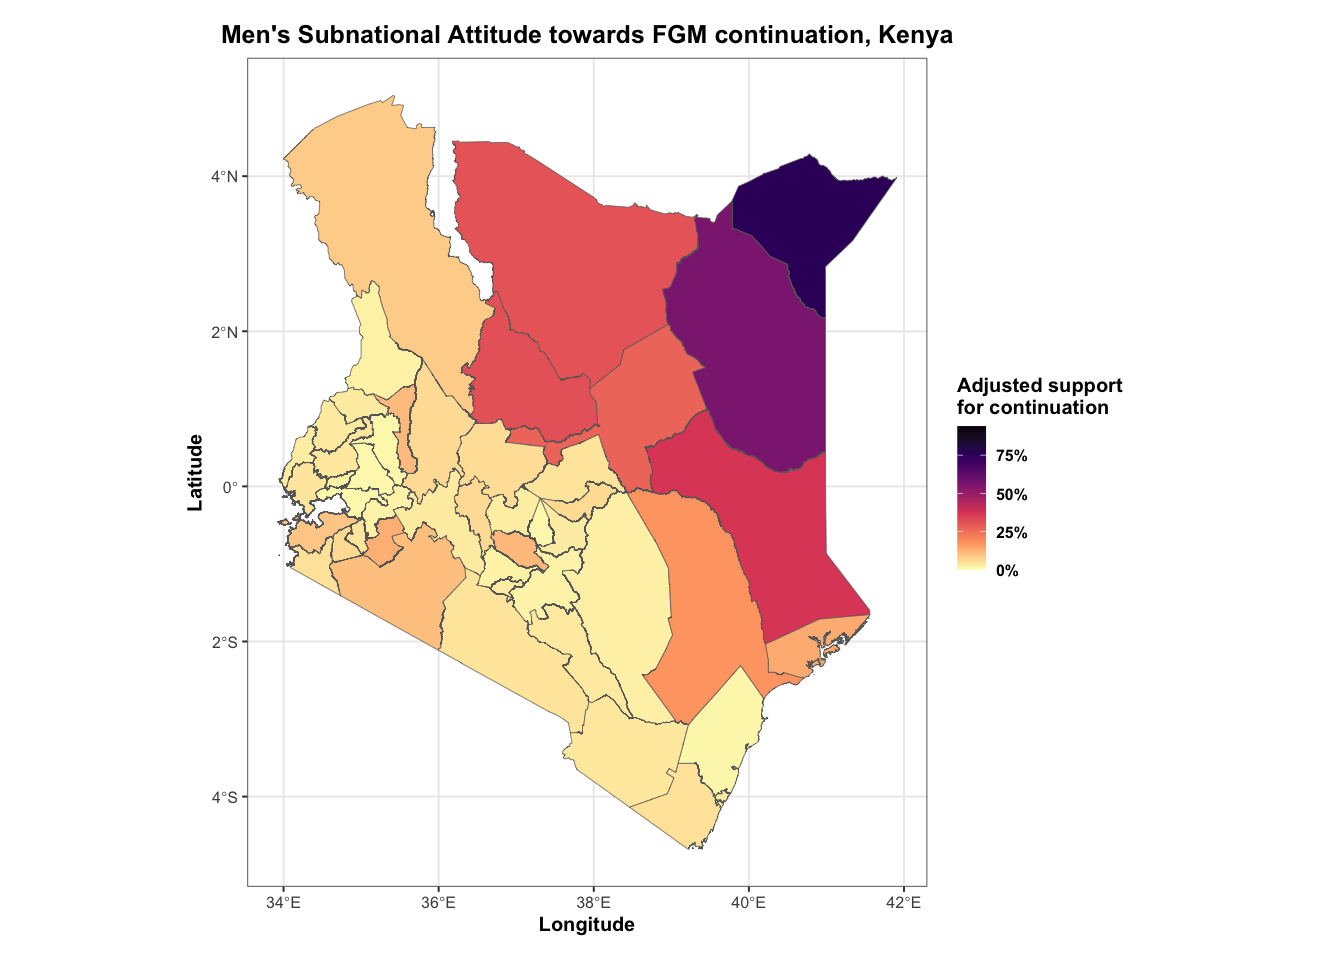

In [21]:
support_scale_upper <- max(
  c(adjusted_state$adjusted_upper, adjusted_state_men$adjusted_upper), na.rm = TRUE
)

attitude_map_data_men <- boundaries |>
  dplyr::left_join(adjusted_state_men, by = c(".region_key" = "region"))

adjusted_attitude_map_men <- ggplot2::ggplot(attitude_map_data_men) +
  ggplot2::geom_sf(ggplot2::aes(fill = adjusted_support), color = "grey40", linewidth = 0.20) +
  ggplot2::scale_fill_viridis_c(
    name = "Adjusted support\nfor continuation",
    option = "magma", direction = -1,
    labels = scales::percent_format(accuracy = 1),
    limits = c(0, support_scale_upper),
    oob = scales::squish, na.value = "grey90"
  ) +
  ggplot2::coord_sf(datum = sf::st_crs(4326)) +
  ggplot2::labs(
    title = paste("Men's Subnational Attitude towards FGM continuation,", country_name),
    x = "Longitude", y = "Latitude"
  ) +
  ggplot2::theme_bw(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(size = 15, hjust = 0.5),
    legend.title = ggplot2::element_text(face = "bold"),
    panel.border = ggplot2::element_rect(color = "grey40", fill = NA),
    plot.margin = ggplot2::margin(15, 15, 15, 15)
  )

print(adjusted_attitude_map_men)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_men_covariate_adjusted_map_v3.png")),
  adjusted_attitude_map_men, width = 9, height = 8, dpi = 300, bg = "white"
)


## 22. Men: residual geographic pattern

The men's BYM2 effect, read as in section 12: a relative log-odds effect after
adjustment, not an attitude estimate.


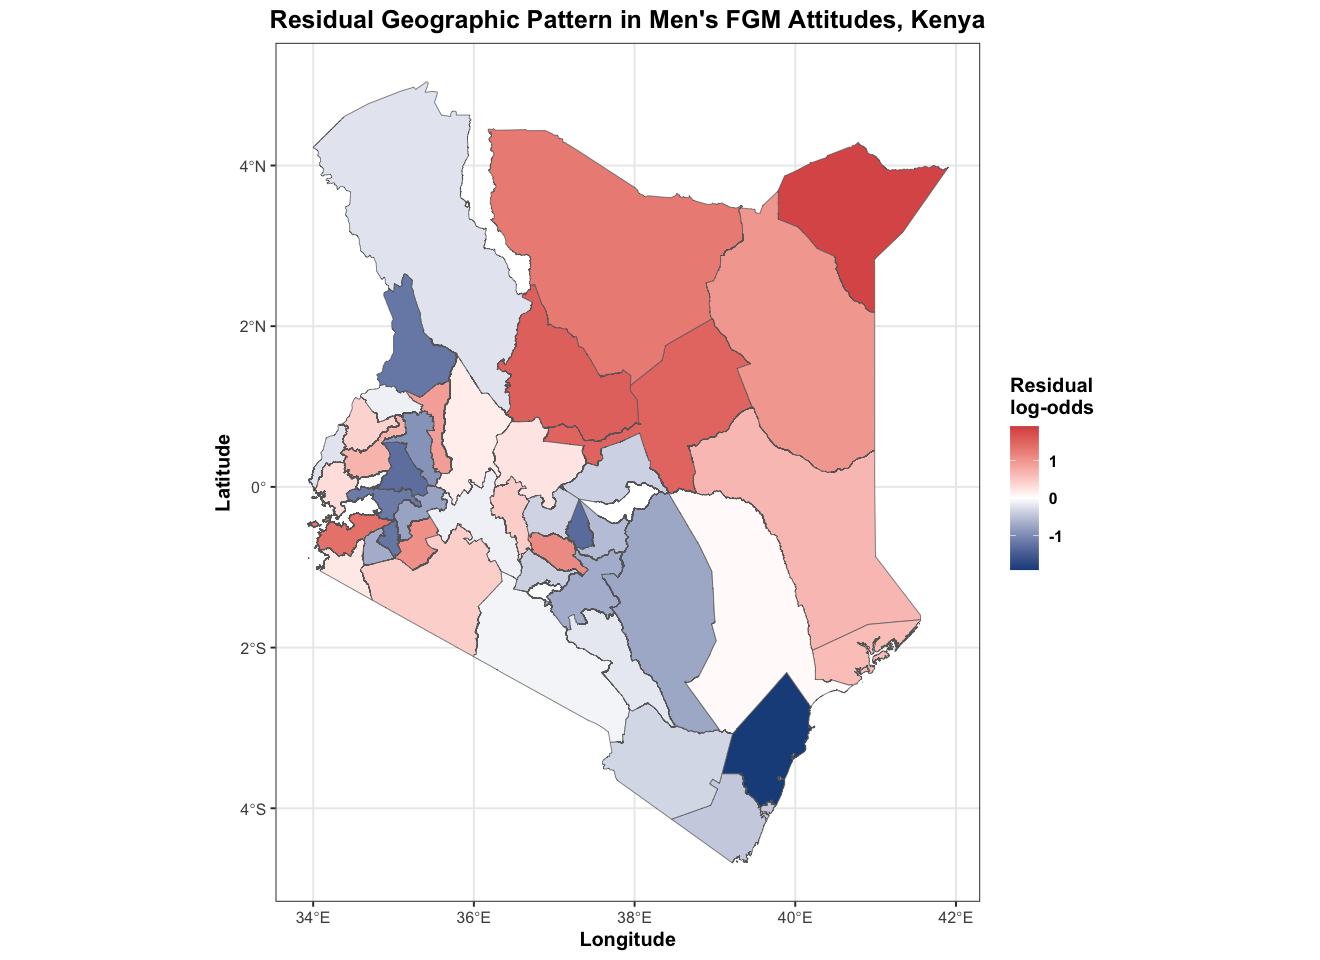

In [22]:
region_lookup_men <- model_data_men |>
  dplyr::distinct(region, region_id) |>
  dplyr::arrange(region_id)

residual_state_men <- adjusted_attitude_model_men$summary.random$region_id |>
  dplyr::filter(ID %in% region_lookup_men$region_id) |>
  dplyr::transmute(
    region_id = ID,
    residual_effect = mean,
    residual_lower = `0.025quant`,
    residual_upper = `0.975quant`
  ) |>
  dplyr::left_join(region_lookup_men, by = "region_id")

residual_map_data_men <- boundaries |>
  dplyr::left_join(residual_state_men, by = c(".region_key" = "region"))

residual_limit_men <- max(abs(residual_map_data_men$residual_effect), na.rm = TRUE)
residual_map_men <- ggplot2::ggplot(residual_map_data_men) +
  ggplot2::geom_sf(ggplot2::aes(fill = residual_effect), color = "grey40", linewidth = 0.20) +
  ggplot2::scale_fill_gradient2(
    name = "Residual\nlog-odds",
    low = "#1D4E89", mid = "white", high = "#D9534F",
    midpoint = 0, limits = c(-residual_limit_men, residual_limit_men)
  ) +
  ggplot2::labs(
    title = paste("Residual Geographic Pattern in Men's FGM Attitudes,", country_name),
    x = "Longitude", y = "Latitude"
  ) +
  ggplot2::theme_bw(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(size = 15, hjust = 0.5)
  )

print(residual_map_men)
readr::write_csv(residual_state_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_residual_spatial_effect_v3.csv")))
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_men_residual_map_v3.png")),
  residual_map_men, width = 9, height = 8, dpi = 300, bg = "white"
)


## 23. Men: validation

Same checks as section 13: how closely the men's covariate-adjusted county estimates
track the men's design-based direct estimates.


# A tibble: 1 × 5
  states_compared correlation_direct_adjusted mean_absolute_difference
            <int>                       <dbl>                    <dbl>
1              47                       0.999                  0.00605
# ℹ 2 more variables: root_mean_squared_difference <dbl>,
#   maximum_absolute_difference <dbl>


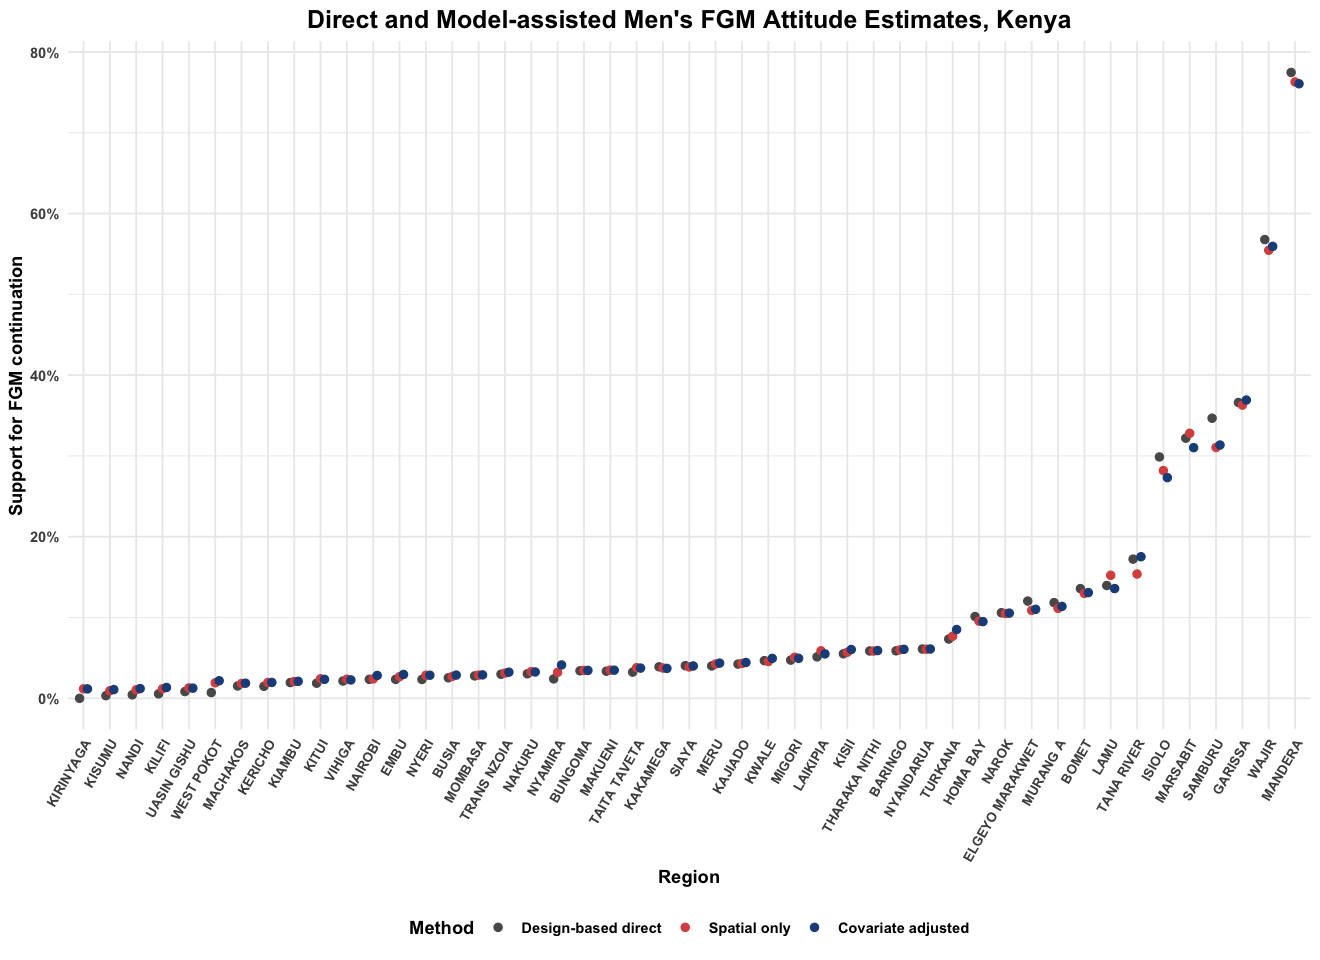

In [23]:
validation_metrics_men <- adjusted_state_men |>
  dplyr::summarise(
    states_compared = sum(stats::complete.cases(direct_support, adjusted_support)),
    correlation_direct_adjusted = stats::cor(direct_support, adjusted_support, use = "complete.obs"),
    mean_absolute_difference = mean(abs(adjusted_support - direct_support), na.rm = TRUE),
    root_mean_squared_difference = sqrt(mean((adjusted_support - direct_support)^2, na.rm = TRUE)),
    maximum_absolute_difference = max(abs(adjusted_support - direct_support), na.rm = TRUE)
  )

validation_long_men <- adjusted_state_men |>
  dplyr::select(region, direct_support, spatial_only, adjusted_support) |>
  tidyr::pivot_longer(-region, names_to = "method", values_to = "support") |>
  dplyr::mutate(
    method = factor(
      method,
      levels = c("direct_support", "spatial_only", "adjusted_support"),
      labels = c("Design-based direct", "Spatial only", "Covariate adjusted")
    )
  )

validation_plot_men <- ggplot2::ggplot(
  validation_long_men,
  ggplot2::aes(x = reorder(region, support), y = support, color = method, group = method)
) +
  ggplot2::geom_point(position = ggplot2::position_dodge(width = 0.45), size = 2) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
  ggplot2::scale_color_manual(
    values = c(
      "Design-based direct" = "grey35",
      "Spatial only" = "#D9534F",
      "Covariate adjusted" = "#1D4E89"
    )
  ) +
  ggplot2::labs(
    title = paste("Direct and Model-assisted Men's FGM Attitude Estimates,", country_name),
    x = "Region", y = "Support for FGM continuation", color = "Method"
  ) +
  ggplot2::theme_minimal(base_size = 11) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(hjust = 0.5, size = 15),
    axis.text.x = ggplot2::element_text(angle = 60, hjust = 1, size = 8),
    legend.position = "bottom"
  )

print(validation_metrics_men)
print(validation_plot_men)

readr::write_csv(validation_metrics_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_validation_metrics_v3.csv")))
readr::write_csv(validation_long_men,
  file.path(output_dir, paste0(country_iso3, "_attitude_men_validation_comparison_v3.csv")))
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_men_validation_v3.png")),
  validation_plot_men, width = 12, height = 7, dpi = 300, bg = "white"
)


## 24. Women and men compared

- **National, design-based.** Women and men are stacked in one survey design (same PSUs
  and strata, each with their own DHS weights). The men − women difference therefore
  gets a design-based standard error that allows for both samples coming from the same
  clusters.
- **National and county, covariate-adjusted.** The section 10 and section 20 estimates
  side by side. The two models are fitted separately, so county differences are reported
  with each sex's 95% interval. Non-overlapping intervals are a conservative sign of a
  real difference.
- **Maps.** Women and men on one shared colour scale, plus a county scatter of men
  against women.


=== National support for continuation, women and men ===
# A tibble: 3 × 8
  sex          direct direct_lower direct_upper p_value adjusted adjusted_lower
  <chr>         <dbl>        <dbl>        <dbl>   <dbl>    <dbl>          <dbl>
1 Women       0.0438       0.0387        0.0488  NA      0.0450          0.0426
2 Men         0.0493       0.0445        0.0540  NA      0.0518          0.0481
3 Men - Women 0.00547     -0.00109       0.0120   0.102  0.00678        NA     
# ℹ 1 more variable: adjusted_upper <dbl>

Counties: 47 | correlation of women's and men's adjusted support: 0.951 | counties where men are higher: 35 | counties with non-overlapping intervals: 9 

# A tibble: 47 × 13
   region          women_adjusted women_lower women_upper women_direct women_n
   <chr>                    <dbl>       <dbl>       <dbl>        <dbl>   <int>
 1 MANDERA                   89.6        83.6        93.9         90.8     396
 2 WAJIR                     80.7        73.1        87           81.9

`height` was translated to `width`.


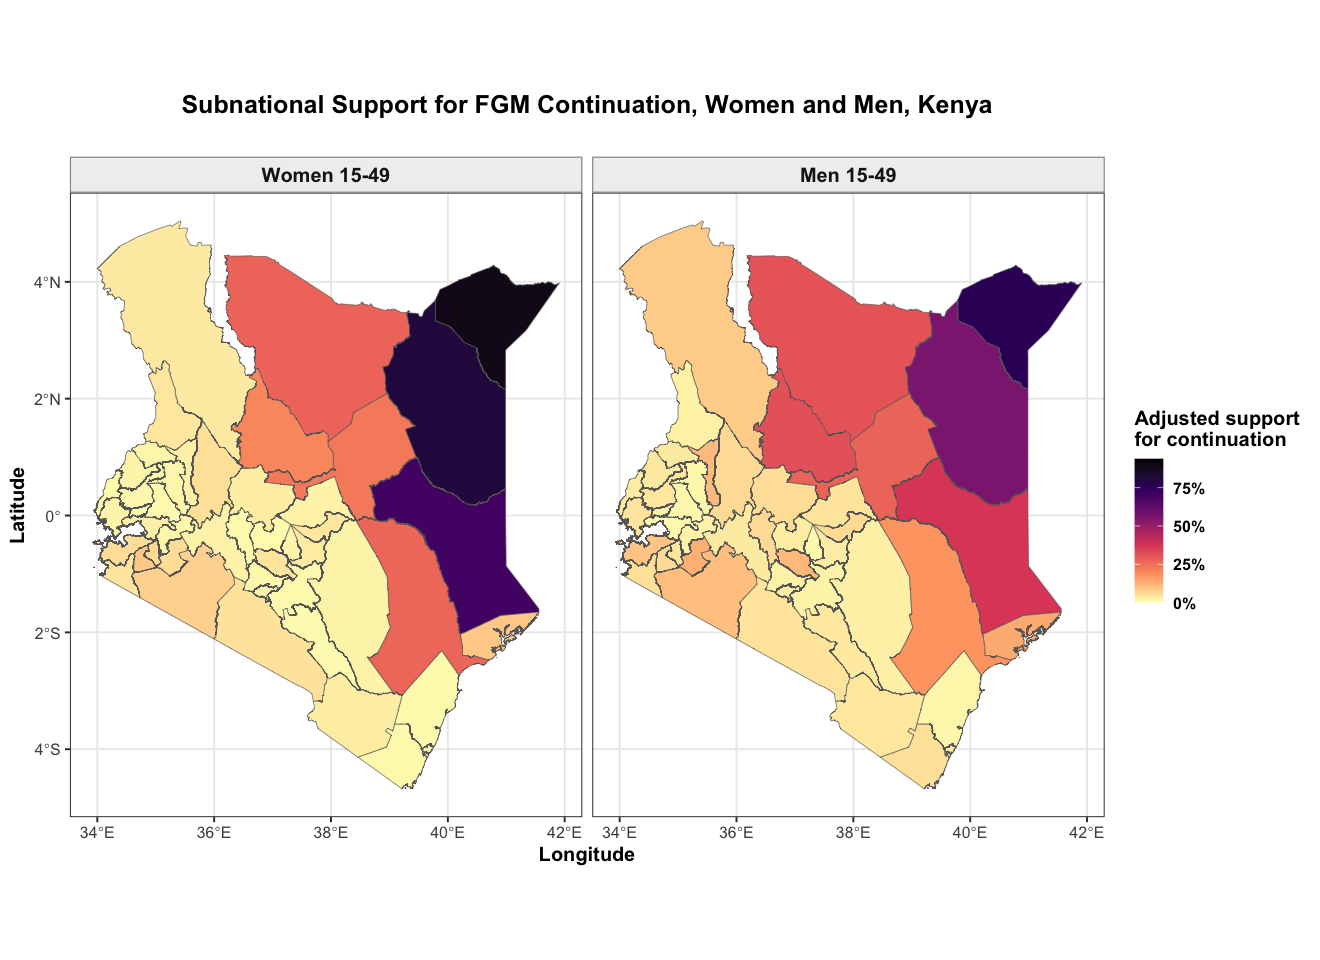

`height` was translated to `width`.


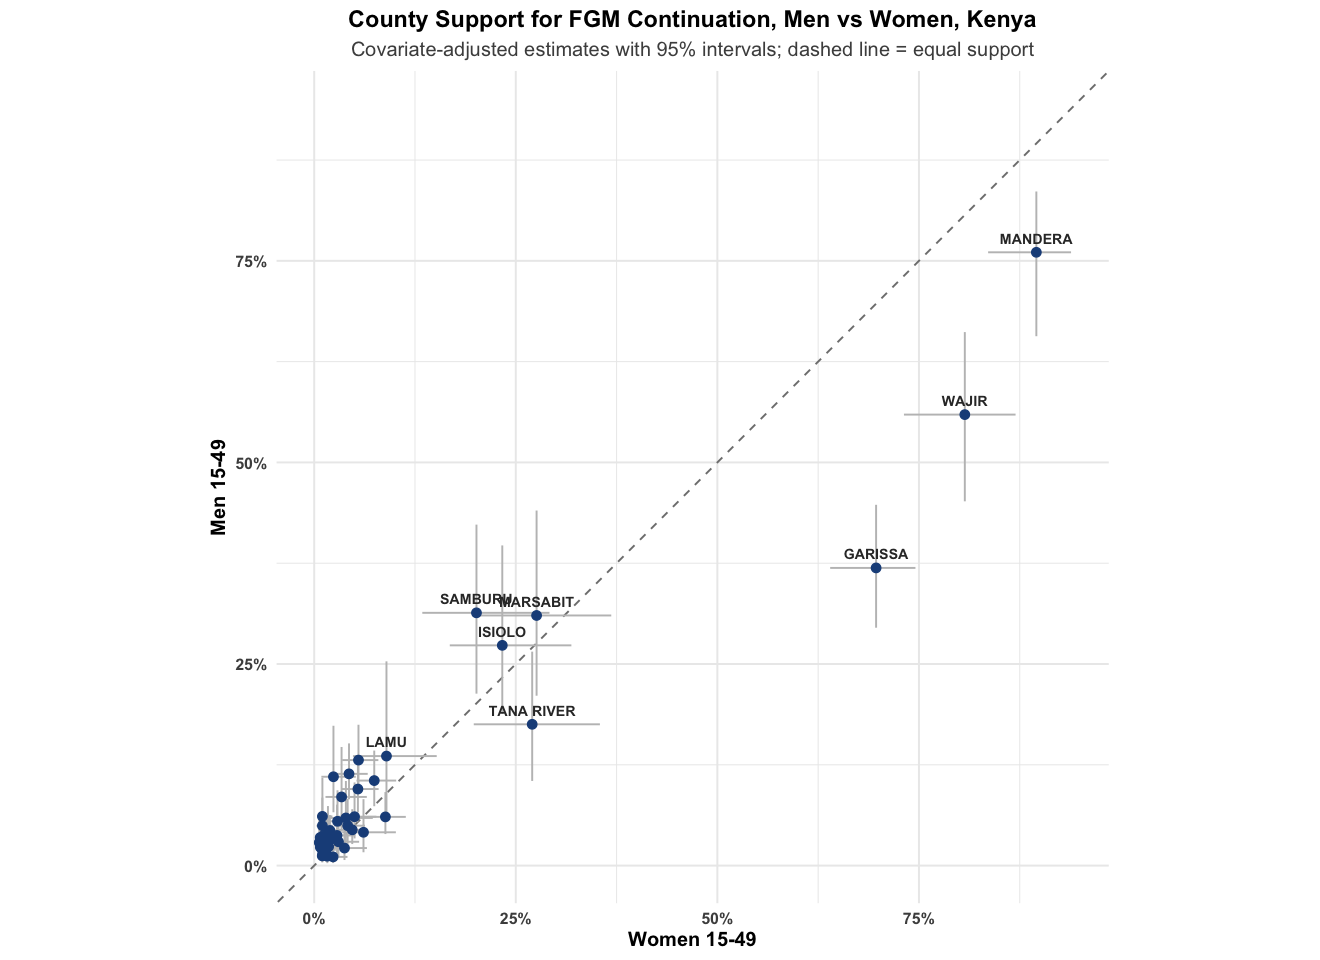

In [27]:
# ---- National, design-based difference --------------------------------
sex_design_data <- dplyr::bind_rows(
  attitude_design_data |>
    dplyr::transmute(sex = "Women", supports_continuation, weight, psu, strata, region),
  men_design_data |>
    dplyr::transmute(sex = "Men", supports_continuation, weight, psu, strata, region)
)
sex_design <- survey::svydesign(
  ids = ~psu, strata = ~strata, weights = ~weight, data = sex_design_data, nest = TRUE
)
sex_direct <- survey::svyby(
  ~supports_continuation, ~sex, sex_design, survey::svymean, covmat = TRUE
)
sex_difference <- survey::svycontrast(sex_direct, quote(Men - Women))
difference_estimate <- as.numeric(stats::coef(sex_difference))
difference_se <- as.numeric(survey::SE(sex_difference))

national_by_sex <- tibble::tibble(
  sex = c("Women", "Men", "Men - Women"),
  direct = c(direct_national$estimate, direct_national_men$estimate, difference_estimate),
  direct_lower = c(direct_national$lower_ci, direct_national_men$lower_ci,
                   difference_estimate - 1.96 * difference_se),
  direct_upper = c(direct_national$upper_ci, direct_national_men$upper_ci,
                   difference_estimate + 1.96 * difference_se),
  p_value = c(NA, NA, 2 * stats::pnorm(-abs(difference_estimate / difference_se))),
  adjusted = c(adjusted_national$estimate, adjusted_national_men$estimate,
               adjusted_national_men$estimate - adjusted_national$estimate),
  adjusted_lower = c(adjusted_national$lower_ci, adjusted_national_men$lower_ci, NA),
  adjusted_upper = c(adjusted_national$upper_ci, adjusted_national_men$upper_ci, NA)
)
cat("=== National support for continuation, women and men ===\n")
print(national_by_sex)

# ---- County comparison --------------------------------------------------
county_by_sex <- adjusted_state |>
  dplyr::select(region, women_adjusted = adjusted_support, women_lower = adjusted_lower,
                women_upper = adjusted_upper, women_direct = direct_support,
                women_n = n_unweighted) |>
  dplyr::full_join(
    adjusted_state_men |>
      dplyr::select(region, men_adjusted = adjusted_support, men_lower = adjusted_lower,
                    men_upper = adjusted_upper, men_direct = direct_support,
                    men_n = n_unweighted),
    by = "region"
  ) |>
  dplyr::mutate(
    men_minus_women = men_adjusted - women_adjusted,
    intervals_separate = men_lower > women_upper | women_lower > men_upper
  ) |>
  dplyr::arrange(dplyr::desc(pmax(women_adjusted, men_adjusted)))

cat("\nCounties:", nrow(county_by_sex),
    "| correlation of women's and men's adjusted support:",
    round(stats::cor(county_by_sex$women_adjusted, county_by_sex$men_adjusted,
                     use = "complete.obs"), 3),
    "| counties where men are higher:", sum(county_by_sex$men_minus_women > 0, na.rm = TRUE),
    "| counties with non-overlapping intervals:",
    sum(county_by_sex$intervals_separate, na.rm = TRUE), "\n\n")
county_by_sex |>
  dplyr::mutate(dplyr::across(
    c(women_adjusted, women_lower, women_upper, women_direct,
      men_adjusted, men_lower, men_upper, men_direct, men_minus_women),
    ~ round(100 * .x, 1)
  )) |>
  print(n = Inf)

readr::write_csv(national_by_sex,
  file.path(output_dir, paste0(country_iso3, "_attitude_women_men_national_v3.csv")))
readr::write_csv(county_by_sex,
  file.path(output_dir, paste0(country_iso3, "_attitude_women_men_by_state_v3.csv")))

# ---- Side-by-side maps on one scale ---------------------------------------
sex_map_data <- dplyr::bind_rows(
  boundaries |>
    dplyr::left_join(adjusted_state |> dplyr::select(region, adjusted_support),
                     by = c(".region_key" = "region")) |>
    dplyr::mutate(sex = "Women 15-49"),
  boundaries |>
    dplyr::left_join(adjusted_state_men |> dplyr::select(region, adjusted_support),
                     by = c(".region_key" = "region")) |>
    dplyr::mutate(sex = "Men 15-49")
) |>
  dplyr::mutate(sex = factor(sex, levels = c("Women 15-49", "Men 15-49")))

sex_map <- ggplot2::ggplot(sex_map_data) +
  ggplot2::geom_sf(ggplot2::aes(fill = adjusted_support), color = "grey40", linewidth = 0.18) +
  ggplot2::facet_wrap(~sex, ncol = 2) +
  ggplot2::scale_fill_viridis_c(
    name = "Adjusted support\nfor continuation",
    option = "magma", direction = -1,
    labels = scales::percent_format(accuracy = 1),
    limits = c(0, support_scale_upper),
    oob = scales::squish, na.value = "grey90"
  ) +
  ggplot2::coord_sf(datum = sf::st_crs(4326)) +
  ggplot2::labs(
    title = paste("Subnational Support for FGM Continuation, Women and Men,", country_name),
    subtitle = "",
    x = "Longitude", y = "Latitude"
  ) +
  ggplot2::theme_bw(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(size = 15, hjust = 0.5),
    plot.subtitle = ggplot2::element_text(face = "plain", hjust = 0.5, color = "grey30"),
    strip.text = ggplot2::element_text(size = 12),
    strip.background = ggplot2::element_rect(fill = "grey94", color = "grey50")
  )

print(sex_map)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_women_men_map_v3.png")),
  sex_map, width = 15, height = 8, dpi = 300, bg = "white"
)

# ---- County scatter: men against women -----------------------------------
scatter_upper <- max(c(county_by_sex$women_upper, county_by_sex$men_upper), na.rm = TRUE)
label_counties <- county_by_sex |>
  dplyr::slice_max(pmax(women_adjusted, men_adjusted), n = 8)

sex_scatter <- ggplot2::ggplot(
  county_by_sex, ggplot2::aes(x = women_adjusted, y = men_adjusted)
) +
  ggplot2::geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "grey50") +
  ggplot2::geom_errorbar(ggplot2::aes(ymin = men_lower, ymax = men_upper),
                         color = "grey75", width = 0) +
  ggplot2::geom_errorbarh(ggplot2::aes(xmin = women_lower, xmax = women_upper),
                          color = "grey75", height = 0) +
  ggplot2::geom_point(color = "#1D4E89", size = 2.3) +
  ggplot2::geom_text(data = label_counties, ggplot2::aes(label = region),
                     size = 3, vjust = -0.9, fontface = "bold", color = "grey20") +
  ggplot2::scale_x_continuous(labels = scales::percent_format(accuracy = 1),
                              limits = c(0, scatter_upper)) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1),
                              limits = c(0, scatter_upper)) +
  ggplot2::coord_equal() +
  ggplot2::labs(
    title = paste("County Support for FGM Continuation, Men vs Women,", country_name),
    subtitle = "Covariate-adjusted estimates with 95% intervals; dashed line = equal support",
    x = "Women 15-49", y = "Men 15-49"
  ) +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(
    text = ggplot2::element_text(face = "bold"),
    plot.title = ggplot2::element_text(size = 14, hjust = 0.5),
    plot.subtitle = ggplot2::element_text(face = "plain", hjust = 0.5, color = "grey30")
  )

print(sex_scatter)
ggplot2::ggsave(
  file.path(output_dir, paste0(country_iso3, "_attitude_women_men_scatter_v3.png")),
  sex_scatter, width = 9, height = 9, dpi = 300, bg = "white"
)


## 25. Men: interpretation and limitations

- Estimates apply to interviewed men aged 15–49 with a known answer to whether FGM
  should continue. Men answering "depends" or "don't know" are excluded, as for women.
- Men have no own-FGM-status covariate. The women's adjusted model includes own status,
  so the two adjusted models do not have identical covariate sets. The design-based
  comparison in section 24 is unaffected by this.
- The covariate-adjusted county intervals are pseudo-posterior, as for women. The
  national men − women difference in section 24 is the only fully design-based test.
- Spatial coincidence of women's and men's support is descriptive, not causal.


In [25]:
cat("FGM Attitudinal Incidence v3 completed.\n")
cat("Selected predictors:", paste(selected_predictors, collapse = ", "), "\n")
cat("Direct national estimate:",
    scales::percent(direct_national$estimate, accuracy = 0.01), "\n")
cat("Adjusted national estimate:",
    scales::percent(adjusted_national$estimate, accuracy = 0.01), "\n")
cat("All outputs saved to:", normalizePath(output_dir, mustWork = FALSE), "\n")
cat("Men's selected predictors:", paste(selected_predictors_men, collapse = ", "), "\n")
cat("Men's direct national estimate:",
    scales::percent(direct_national_men$estimate, accuracy = 0.01), "\n")
cat("Men's adjusted national estimate:",
    scales::percent(adjusted_national_men$estimate, accuracy = 0.01), "\n")
cat("Men - women, design-based:",
    scales::percent(difference_estimate, accuracy = 0.01),
    "(p =", signif(national_by_sex$p_value[3], 3), ")\n")


FGM Attitudinal Incidence v3 completed.
Selected predictors: own_status, age, region, ethnicity, education, wealth, religion, urban_rural 
Direct national estimate: 4.38% 
Adjusted national estimate: 4.50% 
All outputs saved to: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/03_Outputs/KEN/Attitude_v3 
Men's selected predictors: age, region, ethnicity, education, religion, wealth, urban_rural 
Men's direct national estimate: 4.93% 
Men's adjusted national estimate: 5.18% 
Men - women, design-based: 0.55% (p = 0.102 )
